# Network Analysis, Step by Step: The 9/11 Hijacker Network

This notebook walks through a complete social network analysis (SNA) of a small, well-known dataset. Each step introduces a family of network measures, explains **what question it answers**, shows how to compute it with `networkx`, visualizes the result, and interprets what it means for this particular network.

**The data.** The network was compiled by Valdis Krebs from public information released in newspapers after the September 11, 2001 attacks. It contains the 19 hijackers and 43 other individuals associated with them. Nodes are people; an undirected edge indicates a known association between two people (for example having lived or trained together, or having met or communicated). The version used here was distributed by Aaron Clauset and is hosted on the [Netzschleuder network catalog](https://networks.skewed.de/net/terrorists_911).

> V. Krebs, "Mapping networks of terrorist cells." *Connections* 24, 43–52 (2002).

**A note on interpretation.** This is a classic teaching dataset because it is small, real, and has a clear ground truth (who was on which flight). It is also a *reconstruction from press reports after the fact*: ties are missing, some are uncertain, and there are no tie strengths or dates. Every measure below describes **this recorded graph**, not necessarily the true social structure. Keep that in mind whenever a measure seems to say something definitive about a specific person. Questions of data quality are revisited in the final section.

### Contents
1. Setup
2. Loading and cleaning the data
3. Building the graph (and its adjacency matrix)
4. A first look: visualizing the network
5. Global structure: size, density, connectivity
6. Degree and the degree distribution
7. Paths and distances
8. Clustering and triangles
9. Is it a small world? Comparing against null models
10. Centrality: who is "important"?
11. Brokerage, structural holes, and points of vulnerability
12. Cohesive subgroups: cliques, k-cores, communities
13. Mixing patterns: assortativity and homophily
14. Zooming in: the 19 hijackers
15. Robustness: how does the network fragment?
16. Summary cheat sheet
17. Caveats and further reading

## 1. Setup

We only need standard scientific Python: `networkx` for graph algorithms, `pandas` for tables, `numpy` for numerics, and `matplotlib` for plots. (`scipy` must also be installed, since several `networkx` routines rely on it.)

```
pip install networkx pandas numpy matplotlib scipy
```

In [2]:
import re
from collections import Counter

import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from matplotlib.lines import Line2D
import matplotlib.patheffects as pe

plt.rcParams.update({
    "figure.dpi": 100,
    "figure.figsize": (10, 7),
    "axes.spines.top": False,
    "axes.spines.right": False,
    "font.size": 10,
})
pd.set_option("display.precision", 3)
SEED = 42
rng = np.random.default_rng(SEED)


## 2. Loading and cleaning the data

Network data usually comes as two tables:

* a **node list**: one row per entity, with attributes (here: `name` and `group`), and
* an **edge list**: one row per tie, giving the two endpoints.

Place `nodes.csv` and `edges.csv` in the same folder as this notebook (or change `DATA_DIR`). Let's look at the raw files first, because real data almost always needs a bit of cleaning.

In [3]:
DATA_DIR = "."   # folder containing nodes.csv and edges.csv

nodes_raw = pd.read_csv(f"{DATA_DIR}/nodes.csv")
edges_raw = pd.read_csv(f"{DATA_DIR}/edges.csv")

print("Node columns:", list(nodes_raw.columns))
print("Edge columns:", list(edges_raw.columns))
nodes_raw.head()

Node columns: ['# index', ' id', ' name', ' group', ' _pos']
Edge columns: ['# source', ' target']


,# index,id,name,group,_pos
0,0,1,Samir_Kashk,4,"array([-0.45667855, 1.52013403])"
1,1,5,Essid_Sami_Ben_Khemais,4,"array([-0.54533753, 1.40311565])"
2,2,2,Madjid_Sahoune,4,"array([-0.43868948, 1.36990559])"
3,3,3,Fahid_al_Shakri,4,"array([-0.40985337, 1.43747162])"
4,4,4,Lased_Ben_Heni,4,"array([-0.47601296, 1.45845923])"


A few quirks show up immediately:

* Column names carry a leading `#` and leading spaces (`'# index'`, `' name'`).
* `_pos` is a string like `"array([-0.45, 1.52])"`: it is a layout computed by the repository, stored as text.
* The edge list refers to nodes by the **`index`** column (0–61), *not* by `id` (the identifier from Krebs' original data). Mixing these up is a classic source of silent errors.
* One name contains an invisible control character, and names use underscores instead of spaces.

The `group` attribute records the flight each hijacker was aboard (0–3), or 4 for people who were not aboard any flight. The repository notes that the mapping from 0–3 to specific flights **is not documented upstream**. However, comparing the members of each group to the public record of who was aboard each flight gives a one-to-one match, so we use those inferred labels for readability.

In [4]:
nodes = nodes_raw.copy()
nodes.columns = [c.strip().lstrip("#").strip() for c in nodes.columns]

# Clean names: drop control characters, underscores -> spaces
nodes["name"] = (nodes["name"]
                 .str.replace(r"[\x00-\x1f\x7f]", "", regex=True)
                 .str.replace("_", " ")
                 .str.strip())

# Parse the stored layout "array([x, y])" into two floats
xy = nodes["_pos"].str.findall(r"-?\d+\.?\d*(?:e-?\d+)?").apply(lambda v: [float(t) for t in v])
nodes["x"] = xy.str[0]
nodes["y"] = xy.str[1]
nodes = nodes.drop(columns="_pos")

# Group labels (0-3 inferred from the public record of who was on each flight; see text above)
GROUP_LABEL = {0: "AA 11", 1: "AA 77", 2: "UA 93", 3: "UA 175", 4: "Associate (not aboard)"}
GROUP_COLOR = {0: "#E69F00", 1: "#0072B2", 2: "#009E73", 3: "#CC79A7", 4: "#BBBBBB"}
nodes["group_label"] = nodes["group"].map(GROUP_LABEL)
nodes["hijacker"] = nodes["group"] < 4

nodes.head(8)

,index,id,name,group,x,y,group_label,hijacker
0,0,1,Samir Kashk,4,-0.457,1.520,Associate (not aboard),False
1,1,5,Essid Sami Ben Khemais,4,-0.545,1.403,Associate (not aboard),False
2,2,2,Madjid Sahoune,4,-0.439,1.370,Associate (not aboard),False
3,3,3,Fahid al Shakri,4,-0.410,1.437,Associate (not aboard),False
4,4,4,Lased Ben Heni,4,-0.476,1.458,Associate (not aboard),False
5,5,7,Mohamed Bensakhria,4,-0.545,1.473,Associate (not aboard),False
6,6,6,Seifallah ben Hassine,4,-0.589,1.368,Associate (not aboard),False
7,7,8,Mehdi Khammoun,4,-0.549,1.535,Associate (not aboard),False


In [5]:
edges = edges_raw.copy()
edges.columns = ["source", "target"]

# Basic integrity checks
valid = set(nodes["index"])
print("Edges:", len(edges))
print("Endpoints not in node list:", (~edges["source"].isin(valid) | ~edges["target"].isin(valid)).sum())
print("Self-loops:", (edges["source"] == edges["target"]).sum())
undirected_pairs = edges.apply(lambda r: tuple(sorted((r.source, r.target))), axis=1)
print("Duplicate ties (ignoring direction):", undirected_pairs.duplicated().sum())
print()
print(nodes["group_label"].value_counts().to_string())

Edges: 152
Endpoints not in node list: 0
Self-loops: 0
Duplicate ties (ignoring direction): 0

group_label
Associate (not aboard)    43
AA 11                      5
UA 175                     5
AA 77                      5
UA 93                      4


The data is clean: no dangling references, no self-loops, no duplicate ties. We have 19 hijackers (5 + 5 + 5 + 4 per flight) and 43 associates.

## 3. Building the graph

A **graph** $G = (V, E)$ is a set of nodes $V$ and a set of edges $E \subseteq V \times V$. This network is:

* **undirected**: an association between A and B is the same as between B and A;
* **unweighted**: every tie counts the same (we don't know how strong or frequent contacts were);
* **simple**: at most one tie between any pair, no self-loops.

We store `name`, `group`, and `hijacker` as node attributes so we can use them later.

In [6]:
G = nx.Graph()
for r in nodes.itertuples():
    G.add_node(r.index, name=r.name, group=r.group, group_label=r.group_label, hijacker=r.hijacker)
G.add_edges_from(edges[["source", "target"]].itertuples(index=False, name=None))

name = nx.get_node_attributes(G, "name")          # node -> name
idx = {v: k for k, v in name.items()}              # name -> node
group = nx.get_node_attributes(G, "group")
pos = {r.index: (r.x, r.y) for r in nodes.itertuples()}   # repository layout

print(G)

Graph with 62 nodes and 152 edges


### The adjacency matrix

Every graph can also be written as an **adjacency matrix** $A$, where $A_{ij}=1$ if $i$ and $j$ are tied and $0$ otherwise. For an undirected graph $A$ is symmetric. Looking at $A$ directly, with rows sorted by a meaningful attribute, is often more honest than a network drawing: blocks of dots along the diagonal reveal groups that are tied mostly among themselves.

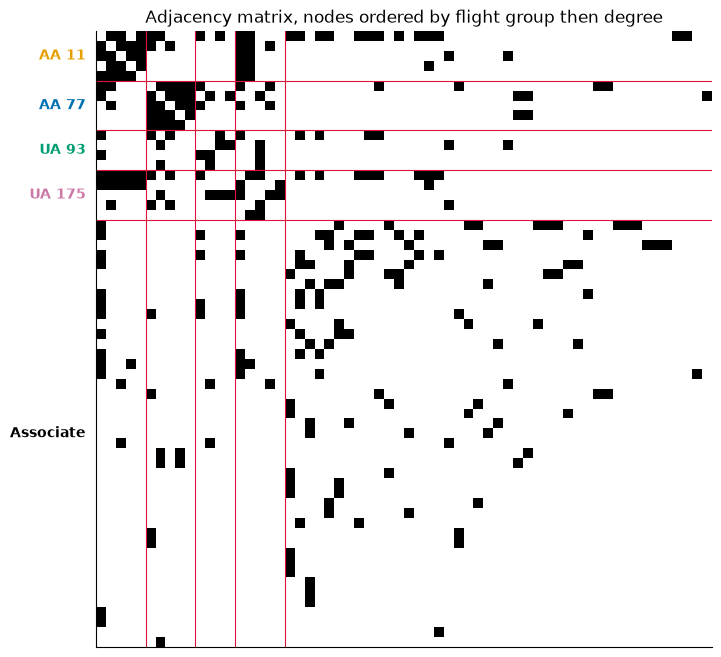

In [7]:
# Order nodes by group, then by degree within group
order = sorted(G.nodes, key=lambda n: (group[n], -G.degree(n)))
A = nx.to_numpy_array(G, nodelist=order)

fig, ax = plt.subplots(figsize=(8, 8))
ax.imshow(A, cmap="Greys", interpolation="none")
# group boundaries
bounds = np.cumsum([sum(group[n] == g for n in order) for g in range(5)])
for b in bounds[:-1]:
    ax.axhline(b - 0.5, color="crimson", lw=0.8)
    ax.axvline(b - 0.5, color="crimson", lw=0.8)
starts = np.r_[0, bounds[:-1]]
for g, (s, e) in enumerate(zip(starts, bounds)):
    ax.text(-1.5, (s + e) / 2 - 0.5, GROUP_LABEL[g].split(" (")[0], ha="right", va="center",
            color=GROUP_COLOR[g] if g < 4 else "black", fontweight="bold")
ax.set_xticks([]); ax.set_yticks([])
ax.set_title("Adjacency matrix, nodes ordered by flight group then degree")
plt.show()

**Reading the matrix.** The top-left blocks (the four flight teams) are relatively dense: hijackers on the same flight tend to be tied to each other. The large bottom-right block (associates) is much sparser, with distinct small clusters along its diagonal. The off-diagonal dots between the flight blocks are ties *across* teams. The first rows of each block (highest degree) carry many of those cross-ties, a hint that a few individuals connect the teams.

## 4. A first look: visualizing the network

Network drawings use a **layout algorithm** to place nodes in 2D. Force-directed layouts (e.g. Fruchterman–Reingold, "spring") treat edges as springs and nodes as repelling charges, so tightly connected nodes end up close together.

We define one helper function and reuse it throughout the notebook so every figure has a consistent look.

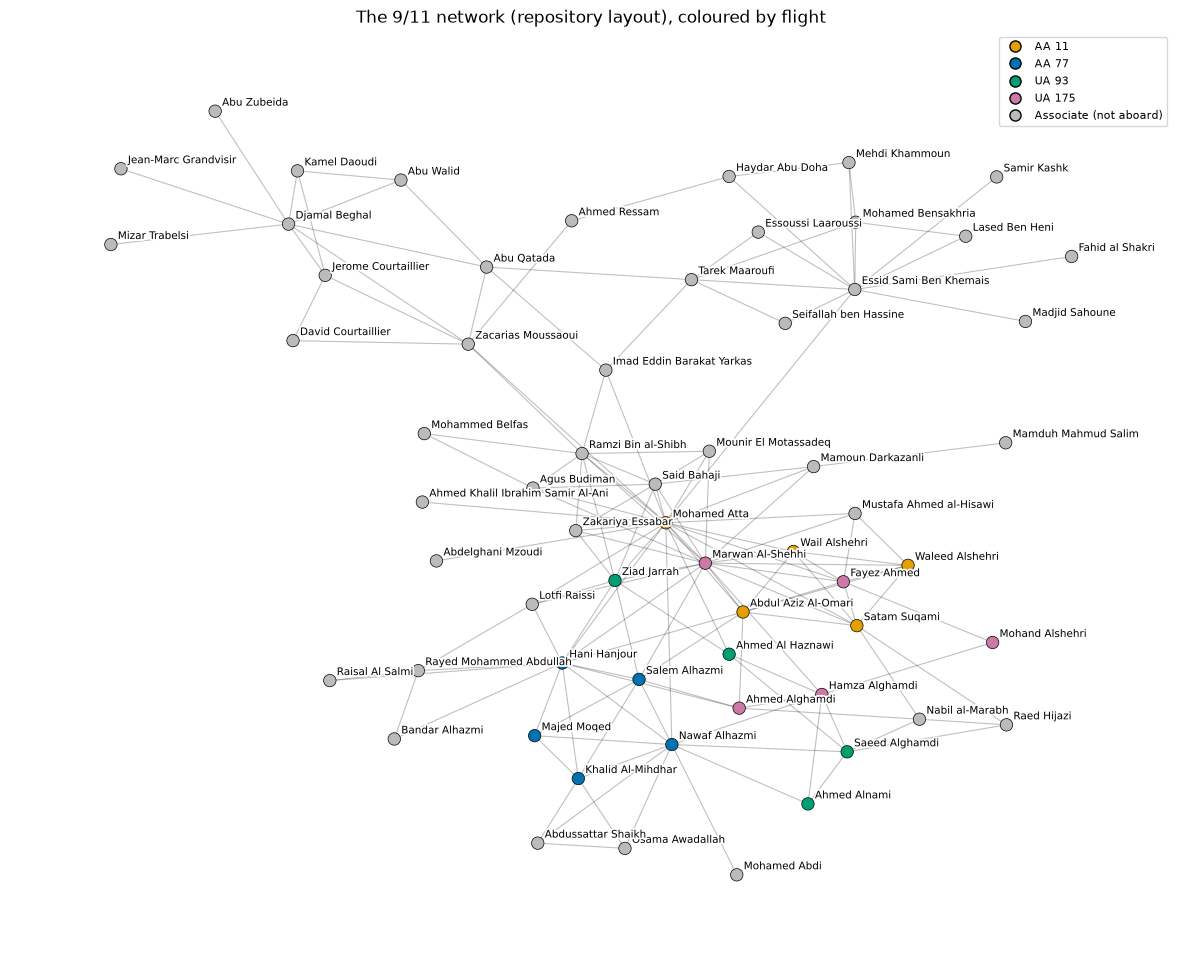

In [8]:
def draw_network(G, pos, ax=None, values=None, cmap="viridis", size=None, color_by_group=False,
                 label_nodes="top", top_k=10, highlight_edges=None, highlight_nodes=None,
                 title=None, colorbar_label=None, node_scale=600, font_size=7, edge_alpha=0.25, figsize=(12, 9)):
    # Draw G with node colour/size options. values: dict node->float used for colour (and size if size is None)
    if ax is None:
        fig, ax = plt.subplots(figsize=figsize)
    nodelist = list(G.nodes)
    # sizes
    s_vals = size if size is not None else values
    if s_vals is None:
        sizes = [80] * len(nodelist)
    else:
        arr = np.array([s_vals[n] for n in nodelist], dtype=float)
        rng_ = arr.max() - arr.min()
        sizes = 30 + node_scale * ((arr - arr.min()) / rng_ if rng_ > 0 else np.ones_like(arr) * 0.3)
    # colours
    sm = None
    if color_by_group:
        colors = [GROUP_COLOR[G.nodes[n]["group"]] for n in nodelist]
    elif values is not None:
        vals = np.array([values[n] for n in nodelist], dtype=float)
        norm = mcolors.Normalize(vals.min(), vals.max())
        colors = plt.get_cmap(cmap)(norm(vals))
        sm = plt.cm.ScalarMappable(norm=norm, cmap=cmap)
    else:
        colors = ["#4C72B0"] * len(nodelist)

    nx.draw_networkx_edges(G, pos, ax=ax, alpha=edge_alpha, width=0.8)
    if highlight_edges:
        nx.draw_networkx_edges(G, pos, edgelist=highlight_edges, ax=ax, width=3, edge_color="crimson")
    nx.draw_networkx_nodes(G, pos, nodelist=nodelist, node_size=sizes, node_color=colors,
                           edgecolors="black", linewidths=0.5, ax=ax)
    if highlight_nodes:
        nx.draw_networkx_nodes(G, pos, nodelist=list(highlight_nodes), node_size=[sizes[nodelist.index(n)] + 120 for n in highlight_nodes],
                               node_color="none", edgecolors="crimson", linewidths=2.5, ax=ax)
    # labels
    if label_nodes == "all":
        lab = {n: G.nodes[n]["name"] for n in nodelist}
    elif label_nodes == "top" and (values is not None or size is not None):
        ref = values if values is not None else size
        lab = {n: G.nodes[n]["name"] for n in sorted(nodelist, key=lambda n: -ref[n])[:top_k]}
    elif isinstance(label_nodes, (list, set, tuple)):
        lab = {n: G.nodes[n]["name"] for n in label_nodes}
    else:
        lab = {}
    for n, t in lab.items():
        x, y = pos[n]
        ax.annotate(t, (x, y), xytext=(5, 4), textcoords="offset points", fontsize=font_size,
                    path_effects=[pe.withStroke(linewidth=2.5, foreground="white")])
    if sm is not None:
        cb = plt.colorbar(sm, ax=ax, fraction=0.035, pad=0.01)
        if colorbar_label: cb.set_label(colorbar_label)
    if color_by_group:
        handles = [Line2D([0], [0], marker="o", ls="", markerfacecolor=GROUP_COLOR[g], markeredgecolor="black",
                          markersize=8, label=GROUP_LABEL[g]) for g in range(5)]
        ax.legend(handles=handles, loc="best", fontsize=8, frameon=True)
    ax.set_title(title or "")
    ax.axis("off")
    return ax

draw_network(G, pos, color_by_group=True, label_nodes="all", font_size=7.5, figsize=(15, 12),
             title="The 9/11 network (repository layout), coloured by flight")
plt.show()

The drawing already suggests a story: a dense core of hijackers at the bottom, and several looser "arms" of associates extending upward (these turn out to be groups based in Europe). One person, **Mohamed Atta**, sits visibly in the middle of things.

### Layouts are not analysis

The *same* graph can look very different under different layouts, and visual impressions can mislead (the Netzschleuder site jokingly calls force-directed drawings "ridiculograms"). Below, the same network is drawn three ways. Distances on the page are an artefact of the algorithm; only the ties are data. This is why the rest of the notebook backs every visual impression with a number.

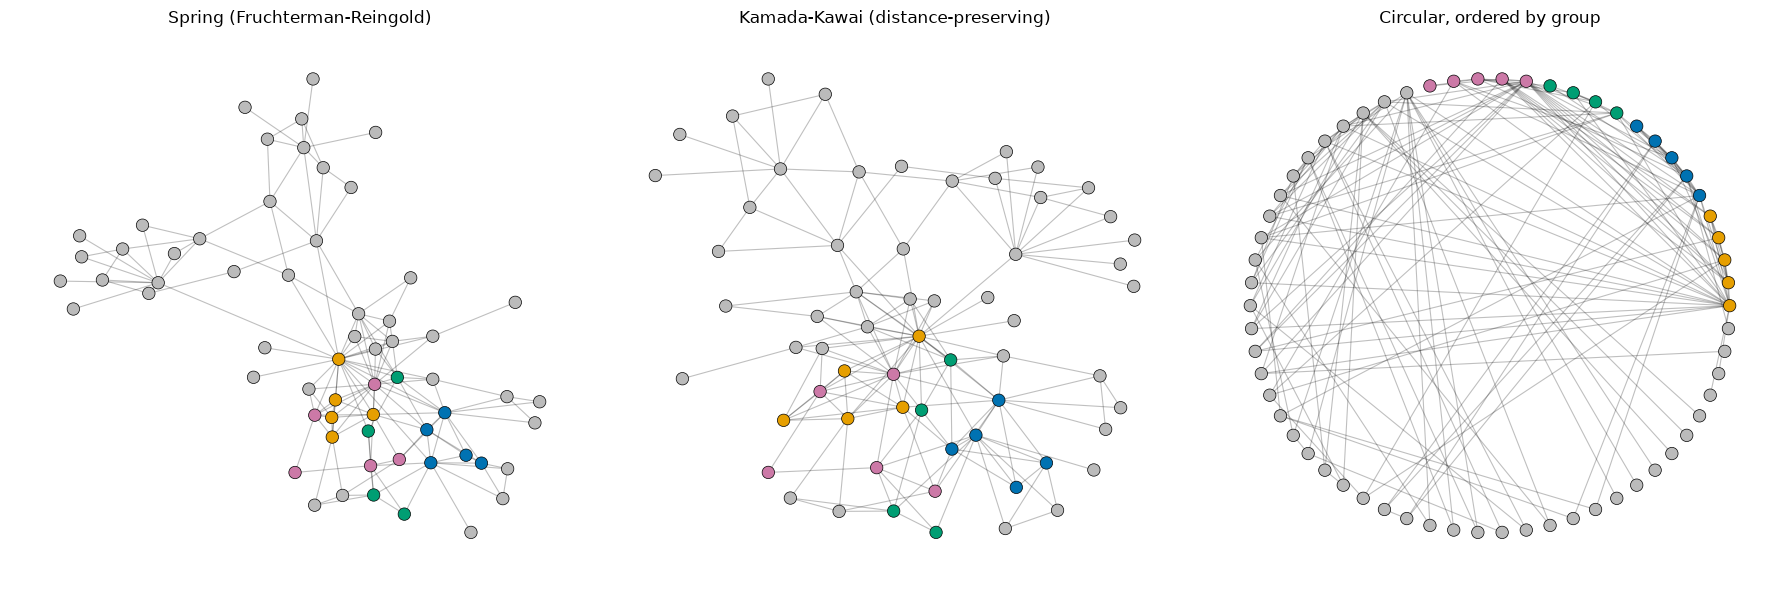

In [9]:
layouts = {
    "Spring (Fruchterman-Reingold)": nx.spring_layout(G, seed=SEED, k=0.25),
    "Kamada-Kawai (distance-preserving)": nx.kamada_kawai_layout(G),
    "Circular, ordered by group": nx.circular_layout(order),
}
fig, axes = plt.subplots(1, 3, figsize=(18, 6))
for ax, (title, p) in zip(axes, layouts.items()):
    draw_network(G, p, ax=ax, color_by_group=True, label_nodes=[], title=title)
    ax.get_legend().remove()
plt.tight_layout()
plt.show()

## 5. Global structure: size, density, connectivity

Before looking at individuals, describe the network as a whole.

| Measure | Question it answers | Definition |
|---|---|---|
| **Order** $n$ and **size** $m$ | How many actors and ties? | $n = \lvert V\rvert$, $m = \lvert E\rvert$ |
| **Density** | What share of all possible ties exist? | $\displaystyle D = \frac{2m}{n(n-1)}$ |
| **Average degree** | How many ties does a typical actor have? | $\langle k\rangle = 2m/n$ |
| **Connected components** | Can everyone reach everyone, directly or indirectly? | maximal sets of mutually reachable nodes |

Density is especially meaningful for covert networks. A dense network moves information quickly and builds trust, but every extra tie is another chance of exposure. Krebs and others have described this as an **efficiency–secrecy trade-off**.

In [10]:
n, m = G.number_of_nodes(), G.number_of_edges()
summary = pd.Series({
    "nodes (n)": n,
    "edges (m)": m,
    "density": nx.density(G),
    "average degree": 2 * m / n,
    "connected components": nx.number_connected_components(G),
    "is connected": nx.is_connected(G),
}, dtype=object)
summary.to_frame("value")

,value
nodes (n),62
edges (m),152
density,0.08
average degree,4.903
connected components,1
is connected,True


**Interpretation.** Only about **8%** of all possible ties are present. Each person has about **5** recorded contacts on average, out of 61 possible. Yet the graph is **connected**: there is a path between every pair of people. Sparse but fully connected is a common signature of social networks generally. For a clandestine group it means nobody needs to know everyone, but everyone is reachable through someone.

## 6. Degree and the degree distribution

**Degree** $k_i$ is the number of ties node $i$ has. It is the simplest centrality measure.

* **Question:** *Who has the most direct contacts? Who is most active or most exposed?*
* **The degree distribution** $P(k)$ asks a structural question: *Is connectivity spread evenly, or concentrated in a few hubs?*

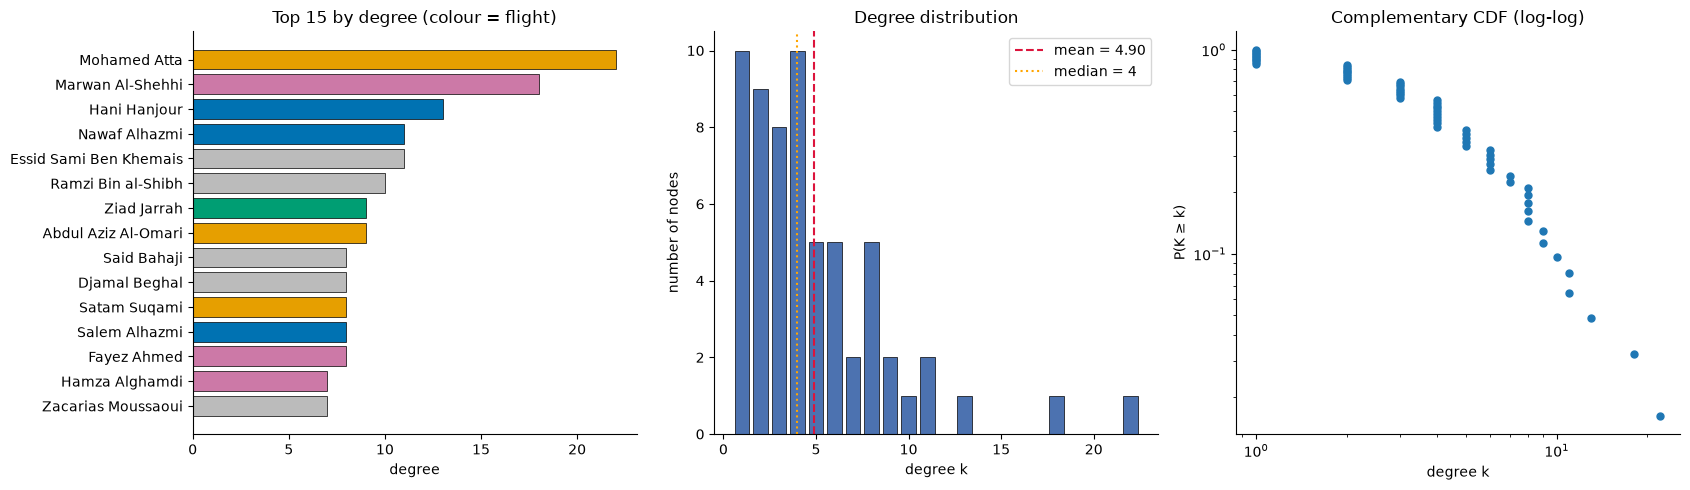

Mohamed Atta              22
Marwan Al-Shehhi          18
Hani Hanjour              13
Nawaf Alhazmi             11
Essid Sami Ben Khemais    11
Ramzi Bin al-Shibh        10
Ziad Jarrah                9
Abdul Aziz Al-Omari        9
Said Bahaji                8
Djamal Beghal              8

std of degree = 4.00; max/mean = 4.5x


In [11]:
deg = dict(G.degree())
deg_s = pd.Series({name[n]: d for n, d in deg.items()}).sort_values(ascending=False)

fig, axes = plt.subplots(1, 3, figsize=(17, 5))

# Top 15 by degree
top = deg_s.head(15)[::-1]
axes[0].barh(top.index, top.values, color=[GROUP_COLOR[group[idx[nm]]] for nm in top.index], edgecolor="black", lw=0.5)
axes[0].set_xlabel("degree"); axes[0].set_title("Top 15 by degree (colour = flight)")

# Histogram
counts = Counter(deg.values())
ks = np.arange(1, max(deg.values()) + 1)
axes[1].bar(ks, [counts.get(k, 0) for k in ks], color="#4C72B0", edgecolor="black", lw=0.5)
axes[1].axvline(np.mean(list(deg.values())), color="crimson", ls="--", label=f"mean = {np.mean(list(deg.values())):.2f}")
axes[1].axvline(np.median(list(deg.values())), color="orange", ls=":", label=f"median = {np.median(list(deg.values())):.0f}")
axes[1].set_xlabel("degree k"); axes[1].set_ylabel("number of nodes"); axes[1].set_title("Degree distribution")
axes[1].legend()

# Complementary CDF on log-log axes
k_sorted = np.sort(list(deg.values()))
ccdf = 1 - np.arange(len(k_sorted)) / len(k_sorted)
axes[2].loglog(k_sorted, ccdf, "o", ms=5)
axes[2].set_xlabel("degree k"); axes[2].set_ylabel("P(K ≥ k)"); axes[2].set_title("Complementary CDF (log-log)")

plt.tight_layout(); plt.show()

print(deg_s.head(10).to_string())
print(f"\nstd of degree = {np.std(list(deg.values())):.2f}; max/mean = {max(deg.values())/np.mean(list(deg.values())):.1f}x")

**Interpretation.**

* The distribution is **right-skewed**. Most people have 1–6 ties, but a handful have far more. **Mohamed Atta** (22 ties) has about 4.5× the average, and **Marwan Al-Shehhi** (18) and **Hani Hanjour** (13) follow. All three were pilots.
* Ten people have only one recorded tie. These are typically peripheral associates who appear in the data through a single contact.
* With only 62 nodes, don't try to fit a power law to the CCDF; there is far too little data to distinguish distributions. The useful observation is the **heterogeneity**: a few hubs and many low-degree nodes.
* High degree also means high **exposure**. A person with 22 recorded ties is the one most likely to be observed.

## 7. Paths and distances

A **path** is a sequence of ties connecting two nodes; the **shortest path** (geodesic) is the one with the fewest steps, and its length is the **distance** $d(i,j)$.

| Measure | Question | Definition |
|---|---|---|
| **Average path length** $L$ | How many steps does it typically take to reach someone? | mean of $d(i,j)$ over all pairs |
| **Diameter** | What's the worst case? | $\max_{i,j} d(i,j)$ |
| **Eccentricity** $e(i)$ | How far is $i$ from the person furthest from them? | $\max_j d(i,j)$ |
| **Radius / center / periphery** | Who is closest to everyone in the worst case? | min eccentricity / nodes with $e = $ radius / nodes with $e = $ diameter |
| **Global efficiency** | How well could information flow, on average? | mean of $1/d(i,j)$ (works even for disconnected graphs) |

Distances matter because influence, information, and trust often decay with distance. In the "small world" literature, two or three steps is considered close.

In [12]:
L = nx.average_shortest_path_length(G)
diam = nx.diameter(G)
rad = nx.radius(G)
ecc = nx.eccentricity(G)
print(f"average path length L = {L:.2f}")
print(f"diameter = {diam}, radius = {rad}")
print(f"global efficiency = {nx.global_efficiency(G):.3f}")
print("\ncenter   (eccentricity = radius):  ", [name[v] for v in nx.center(G)])
print(f"periphery ({len(nx.periphery(G))} nodes, eccentricity = diameter), e.g.:", [name[v] for v in nx.periphery(G)][:6])

average path length L = 2.95
diameter = 5, radius = 3
global efficiency = 0.401

center   (eccentricity = radius):   ['Mohamed Atta', 'Imad Eddin Barakat Yarkas', 'Zacarias Moussaoui', 'Ramzi Bin al-Shibh']
periphery (28 nodes, eccentricity = diameter), e.g.: ['Samir Kashk', 'Madjid Sahoune', 'Fahid al Shakri', 'Lased Ben Heni', 'Mehdi Khammoun', 'Abu Walid']


Let's make a shortest path concrete. Below, we trace one between two hijackers on **different flights**, Ziad Jarrah (UA 93) and Khalid Al-Mihdhar (AA 77), and one between two nodes at opposite ends of the network (a diameter-length path).

Different flights (2 steps): Ziad Jarrah → Hani Hanjour → Khalid Al-Mihdhar
Diameter path    (5 steps): Samir Kashk → Essid Sami Ben Khemais → Tarek Maaroufi → Abu Qatada → Abu Walid → Kamel Daoudi

Number of distinct shortest paths between the diameter pair: 4


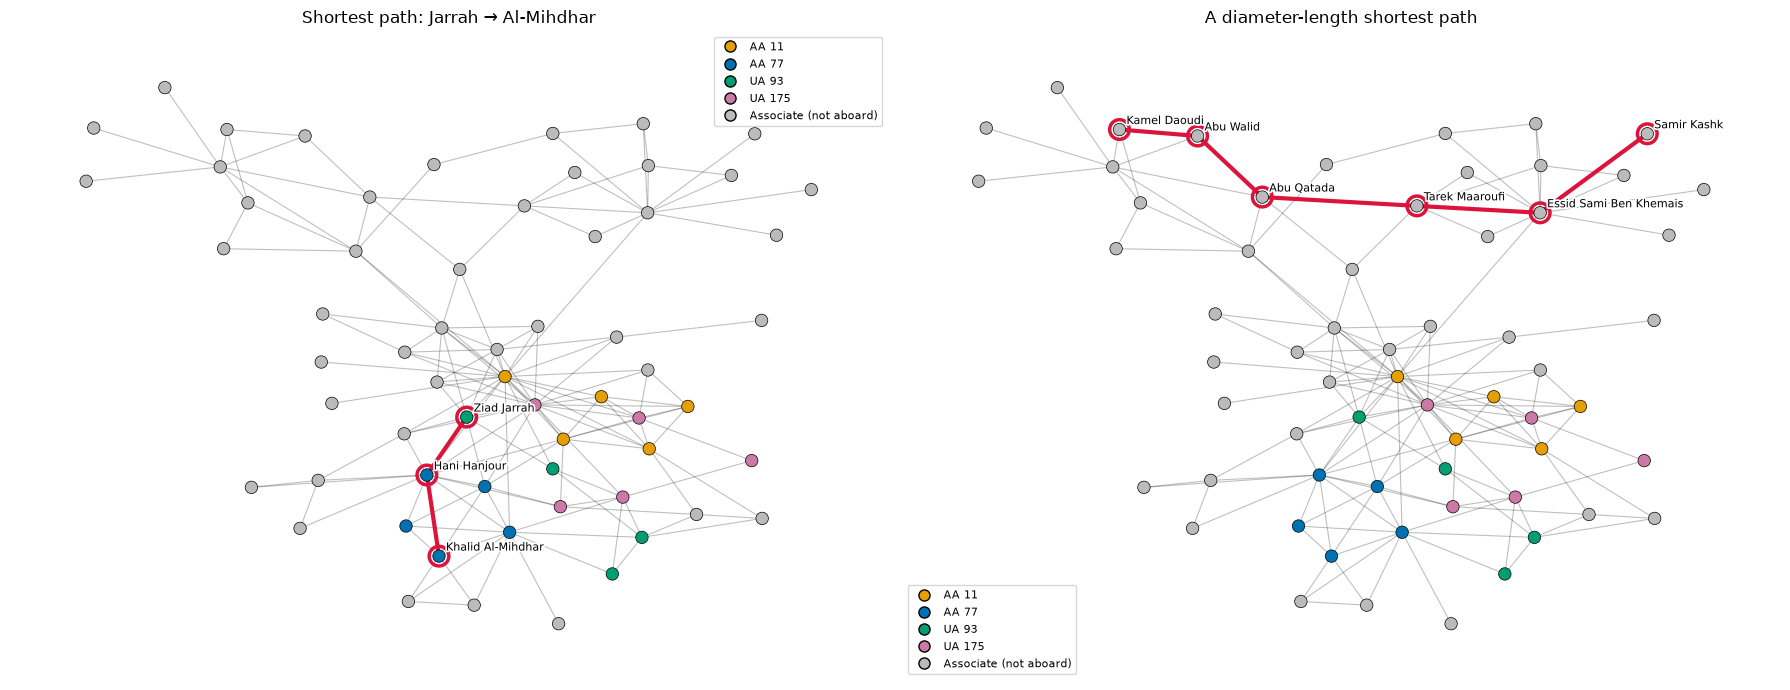

In [13]:
def path_names(a, b):
    p = nx.shortest_path(G, idx[a], idx[b])
    return p, " → ".join(name[v] for v in p)

p1, s1 = path_names("Ziad Jarrah", "Khalid Al-Mihdhar")
# find one pair of nodes at distance = diameter
dist = dict(nx.all_pairs_shortest_path_length(G))
a, b = next((u, v) for u in G for v in G if dist[u][v] == diam)
p2 = nx.shortest_path(G, a, b)
s2 = " → ".join(name[v] for v in p2)
print(f"Different flights ({len(p1)-1} steps): {s1}")
print(f"Diameter path    ({len(p2)-1} steps): {s2}")
print(f"\nNumber of distinct shortest paths between the diameter pair: {len(list(nx.all_shortest_paths(G, a, b)))}")

fig, axes = plt.subplots(1, 2, figsize=(18, 7))
for ax, p, t in [(axes[0], p1, "Shortest path: Jarrah → Al-Mihdhar"), (axes[1], p2, "A diameter-length shortest path")]:
    draw_network(G, pos, ax=ax, color_by_group=True, label_nodes=p, highlight_edges=list(zip(p, p[1:])),
                 highlight_nodes=p, title=t, font_size=8)
plt.tight_layout(); plt.show()

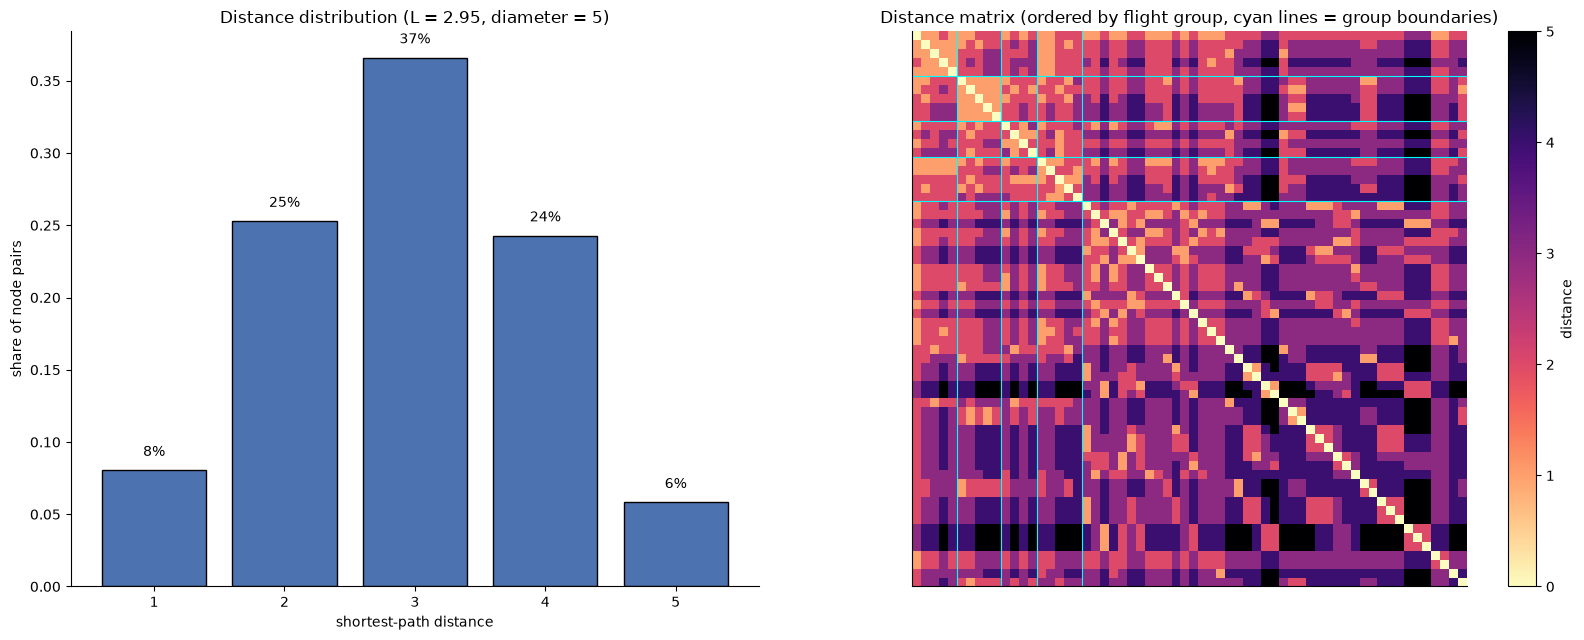

In [14]:
# Distribution of all pairwise distances + distance matrix
D = np.array([[dist[u][v] for v in order] for u in order])
pair_d = D[np.triu_indices(n, 1)]

fig, axes = plt.subplots(1, 2, figsize=(16, 6.5), gridspec_kw={"width_ratios": [1, 1.2]})
vals, cnts = np.unique(pair_d, return_counts=True)
axes[0].bar(vals, cnts / cnts.sum(), color="#4C72B0", edgecolor="black")
for v, c in zip(vals, cnts):
    axes[0].text(v, c / cnts.sum() + 0.01, f"{c/cnts.sum():.0%}", ha="center")
axes[0].set_xlabel("shortest-path distance"); axes[0].set_ylabel("share of node pairs")
axes[0].set_title(f"Distance distribution (L = {L:.2f}, diameter = {diam})")

im = axes[1].imshow(D, cmap="magma_r")
for b_ in bounds[:-1]:
    axes[1].axhline(b_ - 0.5, color="cyan", lw=0.8); axes[1].axvline(b_ - 0.5, color="cyan", lw=0.8)
axes[1].set_xticks([]); axes[1].set_yticks([])
axes[1].set_title("Distance matrix (ordered by flight group, cyan lines = group boundaries)")
plt.colorbar(im, ax=axes[1], fraction=0.04, label="distance")
plt.tight_layout(); plt.show()

**Interpretation.**

* On average any two people are about **3 steps** apart, and nobody is more than **5** steps from anyone else. In a network of 62 people with only 152 ties, this is short.
* About **70%** of all pairs are within 3 steps.
* The **center** (minimum eccentricity) includes Mohamed Atta, Ramzi Bin al-Shibh, and two members of the European associate clusters (Imad Eddin Barakat Yarkas and Zacarias Moussaoui). Being central in this worst-case sense means being able to reach the *entire* network quickly.
* The distance matrix shows the flight teams as dark (close) blocks in the top-left. The light patches in the associate region are associate sub-groups that are far from one another.

## 8. Clustering and triangles

**Clustering** measures the tendency of ties to form **triangles**: *if A knows B and A knows C, do B and C know each other?*

* **Local clustering coefficient:** $C_i = \dfrac{2T_i}{k_i(k_i-1)}$, the fraction of pairs of $i$'s neighbours that are tied to each other ($T_i$ = number of triangles through $i$). It answers: *Is this person embedded in a tight-knit group, or do they connect people who don't otherwise know each other?*
* **Transitivity (global clustering):** $C = \dfrac{3 \times \#\text{triangles}}{\#\text{connected triples}}$. It answers: *Overall, how "cliquish" is the network?*
* **Average clustering** $\bar C = \frac{1}{n}\sum_i C_i$ is a different global summary. It weights every node equally, so low-degree nodes (which easily get $C_i=1$) pull it up. The two numbers are not interchangeable.

transitivity (global clustering) = 0.361
average local clustering         = 0.486
number of triangles              = 131
density (for comparison)         = 0.080


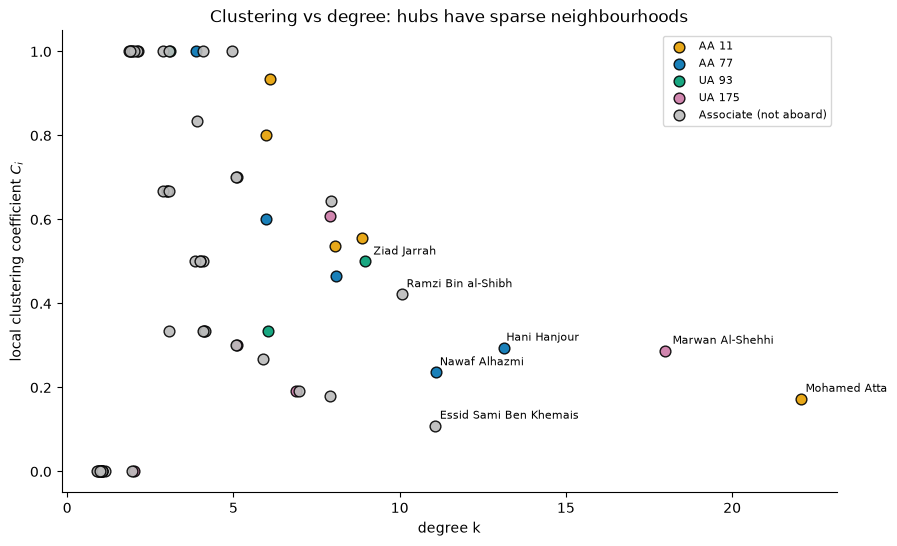

In [15]:
clust = nx.clustering(G)
tri = nx.triangles(G)
print(f"transitivity (global clustering) = {nx.transitivity(G):.3f}")
print(f"average local clustering         = {nx.average_clustering(G):.3f}")
print(f"number of triangles              = {sum(tri.values()) // 3}")
print(f"density (for comparison)         = {nx.density(G):.3f}")

fig, ax = plt.subplots(figsize=(10, 6))
for g in range(5):
    ns = [v for v in G if group[v] == g]
    ax.scatter([deg[v] + rng.uniform(-0.15, 0.15) for v in ns], [clust[v] for v in ns],
               c=GROUP_COLOR[g], edgecolors="black", s=60, label=GROUP_LABEL[g], alpha=0.9)
for v in sorted(G, key=lambda v: -deg[v])[:7]:
    ax.annotate(name[v], (deg[v], clust[v]), xytext=(5, 5), textcoords="offset points", fontsize=8)
ax.set_xlabel("degree k"); ax.set_ylabel("local clustering coefficient $C_i$")
ax.set_title("Clustering vs degree: hubs have sparse neighbourhoods")
ax.legend(fontsize=8); plt.show()

**Interpretation.**

* Transitivity is **0.36**, about **4.5×** the density (0.08). If ties were placed at random, the chance that two neighbours of a node are tied would be about the density. The network is therefore far more cliquish than chance would produce: people who share a contact tend to know each other too.
* The scatter shows a typical pattern: **clustering falls as degree rises**. Low-degree people sit inside small, closed groups ($C_i$ near 1). The hubs (Atta, Al-Shehhi, Hanjour) have neighbourhoods that are mostly *not* connected to each other. Their contacts come from different circles, so the hubs act as the links between those circles. Section 11 measures this directly.

## 9. Is it a small world? Comparing against null models

A raw number like "clustering = 0.36" means little on its own. Network scientists judge measures against a **null model**: a random graph that preserves some properties of the real one, so we can ask *is this value higher or lower than we'd expect by chance?*

We use two null models:

1. **Erdős–Rényi** $G(n,m)$: same number of nodes and edges, ties placed uniformly at random.
2. **Degree-preserving rewiring** (configuration model via double edge swaps): every node keeps *exactly* its degree, but who is tied to whom is shuffled. This is a stricter test, since it controls for the hubs.

A **small-world** network (Watts & Strogatz, 1998) has *high clustering* like a regular lattice but *short paths* like a random graph: $C \gg C_\text{rand}$ while $L \approx L_\text{rand}$.

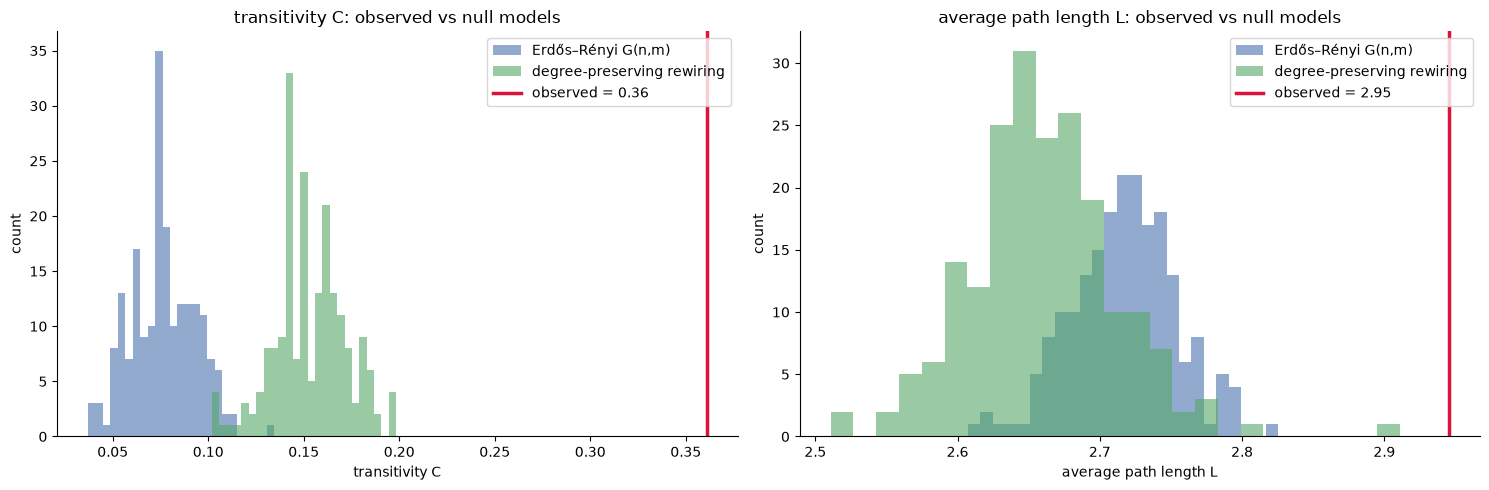

small-world coefficient sigma = (C/C_rand)/(L/L_rand) = 4.4   (sigma > 1 suggests small-world)


,observed,Erdős–Rényi mean,rewired mean,observed / ER
transitivity C,0.361,0.076,0.153,4.718
avg path length L,2.946,2.716,2.660,1.084


In [16]:
def null_stats(make, n_samples):
    Cs, Ls = [], []
    for s in range(n_samples):
        R = make(s)
        Cs.append(nx.transitivity(R))
        if nx.is_connected(R):
            Ls.append(nx.average_shortest_path_length(R))
        else:  # use the largest component if the random graph happens to be disconnected
            Ls.append(nx.average_shortest_path_length(R.subgraph(max(nx.connected_components(R), key=len))))
    return np.array(Cs), np.array(Ls)

def er(s):
    return nx.gnm_random_graph(n, m, seed=s)

def rewired(s):
    R = G.copy()
    nx.double_edge_swap(R, nswap=10 * m, max_tries=100 * m, seed=s)
    return R

C_obs = nx.transitivity(G)
C_er, L_er = null_stats(er, 200)
C_cf, L_cf = null_stats(rewired, 200)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for ax, (obs, a_, b_, lab) in zip(axes, [(C_obs, C_er, C_cf, "transitivity C"), (L, L_er, L_cf, "average path length L")]):
    ax.hist(a_, bins=25, alpha=0.6, label="Erdős–Rényi G(n,m)", color="#4C72B0")
    ax.hist(b_, bins=25, alpha=0.6, label="degree-preserving rewiring", color="#55A868")
    ax.axvline(obs, color="crimson", lw=2.5, label=f"observed = {obs:.2f}")
    ax.set_xlabel(lab); ax.set_ylabel("count"); ax.legend(); ax.set_title(f"{lab}: observed vs null models")
plt.tight_layout(); plt.show()

res = pd.DataFrame({
    "observed": [C_obs, L],
    "Erdős–Rényi mean": [C_er.mean(), L_er.mean()],
    "rewired mean": [C_cf.mean(), L_cf.mean()],
}, index=["transitivity C", "avg path length L"])
res["observed / ER"] = res["observed"] / res["Erdős–Rényi mean"]
sigma = (C_obs / C_er.mean()) / (L / L_er.mean())
print(f"small-world coefficient sigma = (C/C_rand)/(L/L_rand) = {sigma:.1f}   (sigma > 1 suggests small-world)")
res

**Interpretation.**

* Clustering is about **5× higher** than in Erdős–Rényi graphs, and still more than **2× higher** than in degree-preserving rewired graphs. The triangles are therefore *not* just a by-product of having a few hubs; there is genuine local cohesion.
* Average path length is only slightly *longer* than in the random graphs (≈1.1×).
* High clustering with near-random path lengths is the definition of a **small world**. Small worlds combine dense local groups (good for trust and coordination) with a few long-range ties (good for reach). The null-model comparison makes this claim quantitative.

## 10. Centrality: who is "important"?

"Importance" in a network has many meanings, and each **centrality measure** formalizes a different one. Choosing a measure means choosing a question:

| Measure | Question it answers | Idea | Formula (normalized) |
|---|---|---|---|
| **Degree** | Who has the most direct contacts? | activity / exposure | $C_D(i) = \dfrac{k_i}{n-1}$ |
| **Closeness** | Who can reach everyone else in the fewest steps? | speed of access | $C_C(i) = \dfrac{n-1}{\sum_j d(i,j)}$ |
| **Betweenness** | Who sits on the paths *between* others? | brokerage / control of flows | $C_B(i) = \dfrac{2}{(n-1)(n-2)}\sum_{s<t,\; s,t\ne i} \dfrac{\sigma_{st}(i)}{\sigma_{st}}$ |
| **Eigenvector** | Who is connected to *well-connected* people? | status / prestige | $x_i = \dfrac{1}{\lambda}\sum_j A_{ij}x_j$ |
| **PageRank** | Where does a random walker spend time? | eigenvector variant with teleportation | $PR_i = \dfrac{1-\alpha}{n} + \alpha\sum_j \dfrac{A_{ji}}{k_j}PR_j$ |

($\sigma_{st}$ is the number of shortest paths from $s$ to $t$; $\sigma_{st}(i)$ the number of those passing through $i$.)

A useful way to remember them: **degree** counts your ties, **closeness** measures how far you are from everyone, **betweenness** measures how often you are in the way, and **eigenvector/PageRank** measure who your contacts are.

In [17]:
cent = pd.DataFrame({
    "name": pd.Series(name),
    "group": pd.Series(group).map(GROUP_LABEL),
    "degree": pd.Series(nx.degree_centrality(G)),
    "closeness": pd.Series(nx.closeness_centrality(G)),
    "betweenness": pd.Series(nx.betweenness_centrality(G)),
    "eigenvector": pd.Series(nx.eigenvector_centrality(G, max_iter=1000)),
    "pagerank": pd.Series(nx.pagerank(G, alpha=0.85)),
})
measures = ["degree", "closeness", "betweenness", "eigenvector", "pagerank"]
cent.sort_values("betweenness", ascending=False).head(12).set_index("name")

,group,degree,closeness,betweenness,eigenvector,pagerank
name,,,,,,
Mohamed Atta,AA 11,0.361,0.581,0.587,0.413,0.061
Essid Sami Ben Khemais,Associate (not aboard),0.180,0.430,0.251,0.059,0.048
Zacarias Moussaoui,Associate (not aboard),0.115,0.433,0.227,0.082,0.026
Nawaf Alhazmi,AA 77,0.180,0.439,0.154,0.144,0.032
Hani Hanjour,AA 77,0.213,0.442,0.126,0.247,0.035
Djamal Beghal,Associate (not aboard),0.131,0.332,0.121,0.015,0.036
Marwan Al-Shehhi,UA 175,0.295,0.462,0.089,0.400,0.045
Satam Suqami,AA 11,0.131,0.407,0.050,0.193,0.021
Abu Qatada,Associate (not aboard),0.082,0.343,0.049,0.023,0.020


### Seeing the measures on the network

Each panel below sizes and colours nodes by one measure; the top 6 are labelled. Notice who grows and shrinks from panel to panel.

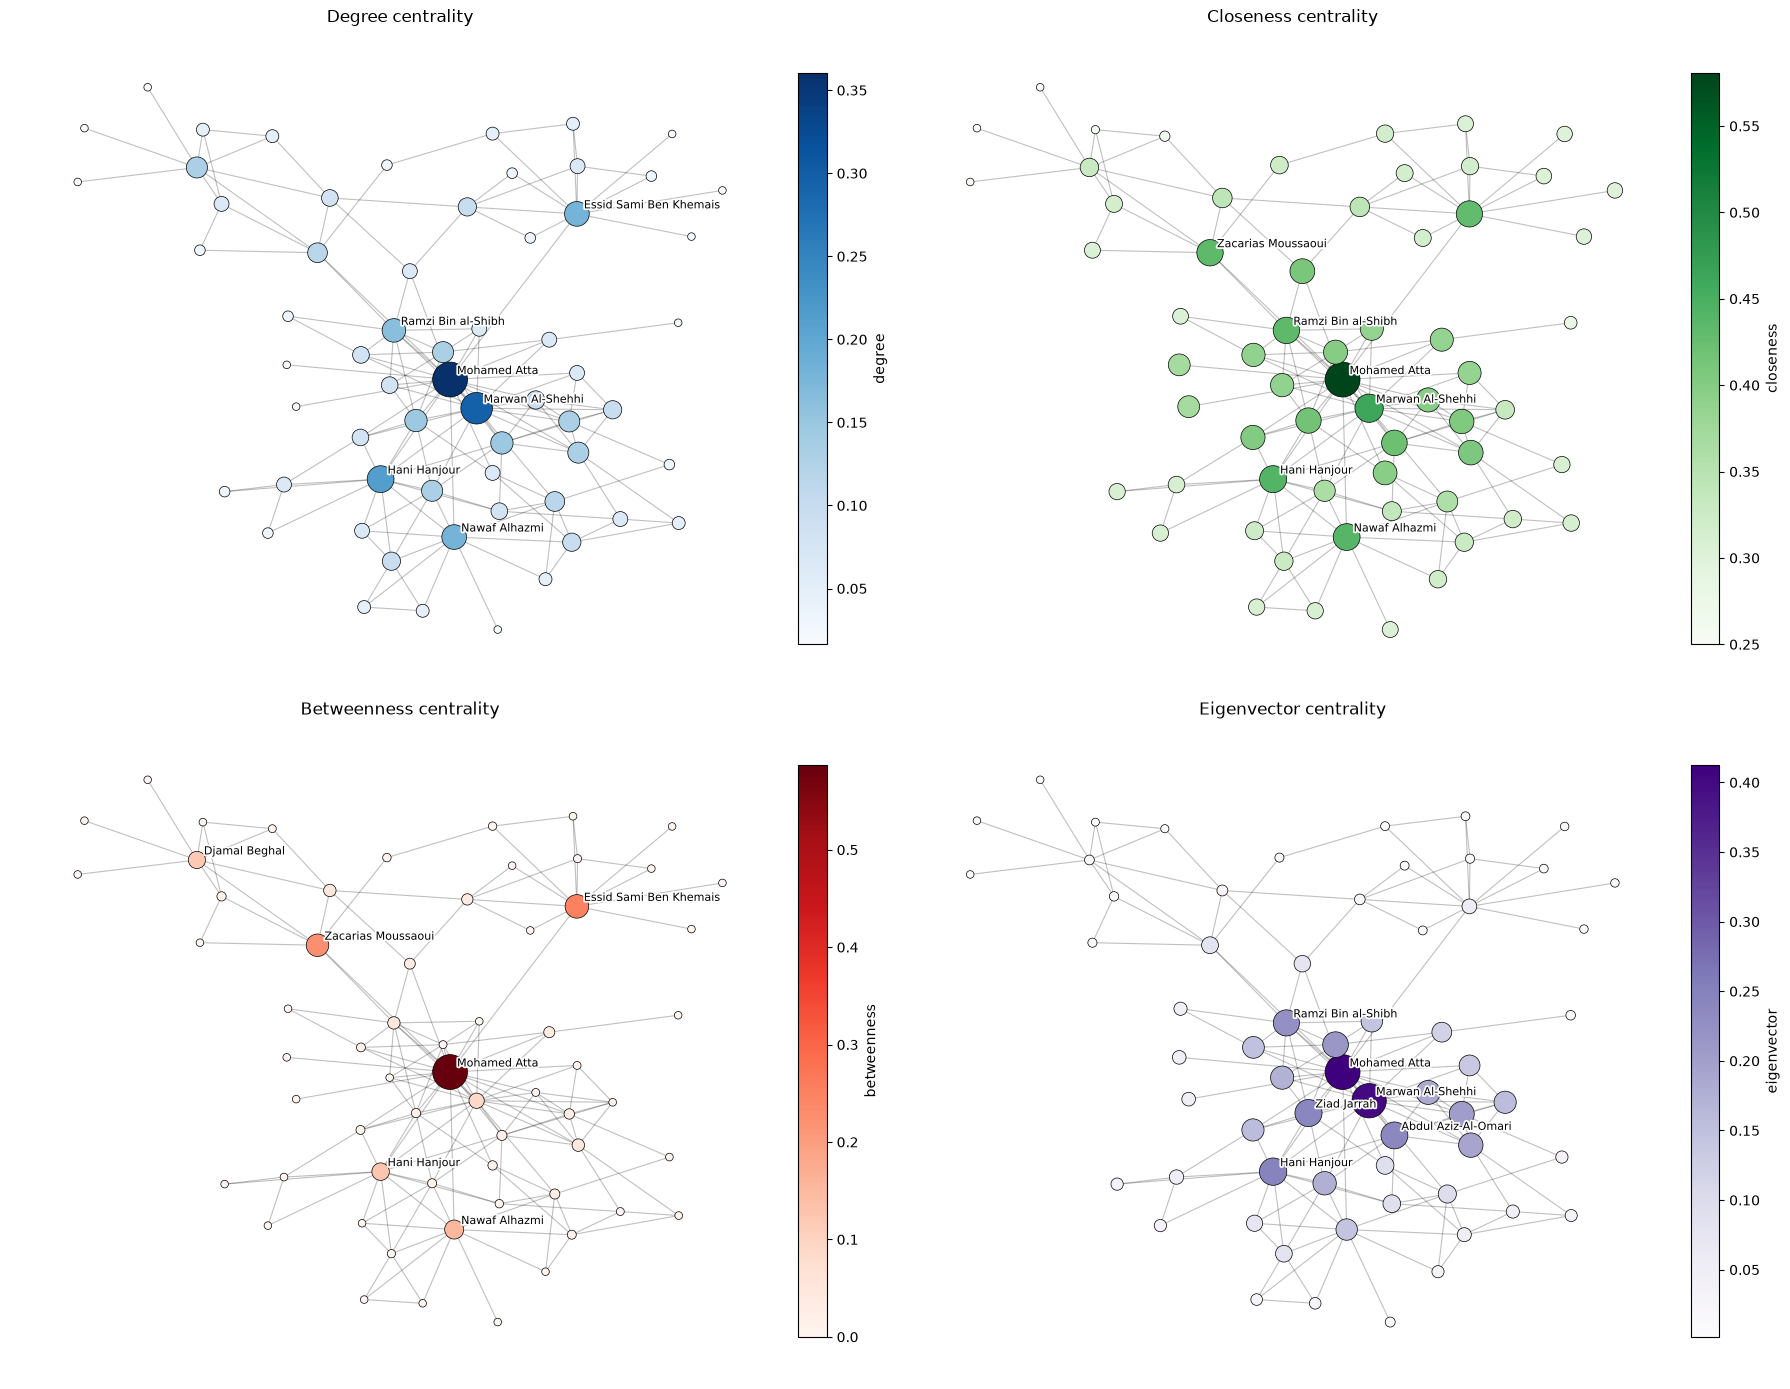

In [18]:
fig, axes = plt.subplots(2, 2, figsize=(18, 14))
for ax, meas, cmap in zip(axes.flat, ["degree", "closeness", "betweenness", "eigenvector"],
                          ["Blues", "Greens", "Reds", "Purples"]):
    draw_network(G, pos, ax=ax, values=cent[meas].to_dict(), cmap=cmap, top_k=6,
                 title=f"{meas.capitalize()} centrality", colorbar_label=meas, font_size=8)
plt.tight_layout(); plt.show()

### Do the measures agree?

Compare the **ranks** people get under each measure. The heatmap shows ranks (1 = most central) for everyone who is top-8 on at least one measure; the second panel shows Spearman rank correlations between measures across all 62 nodes.

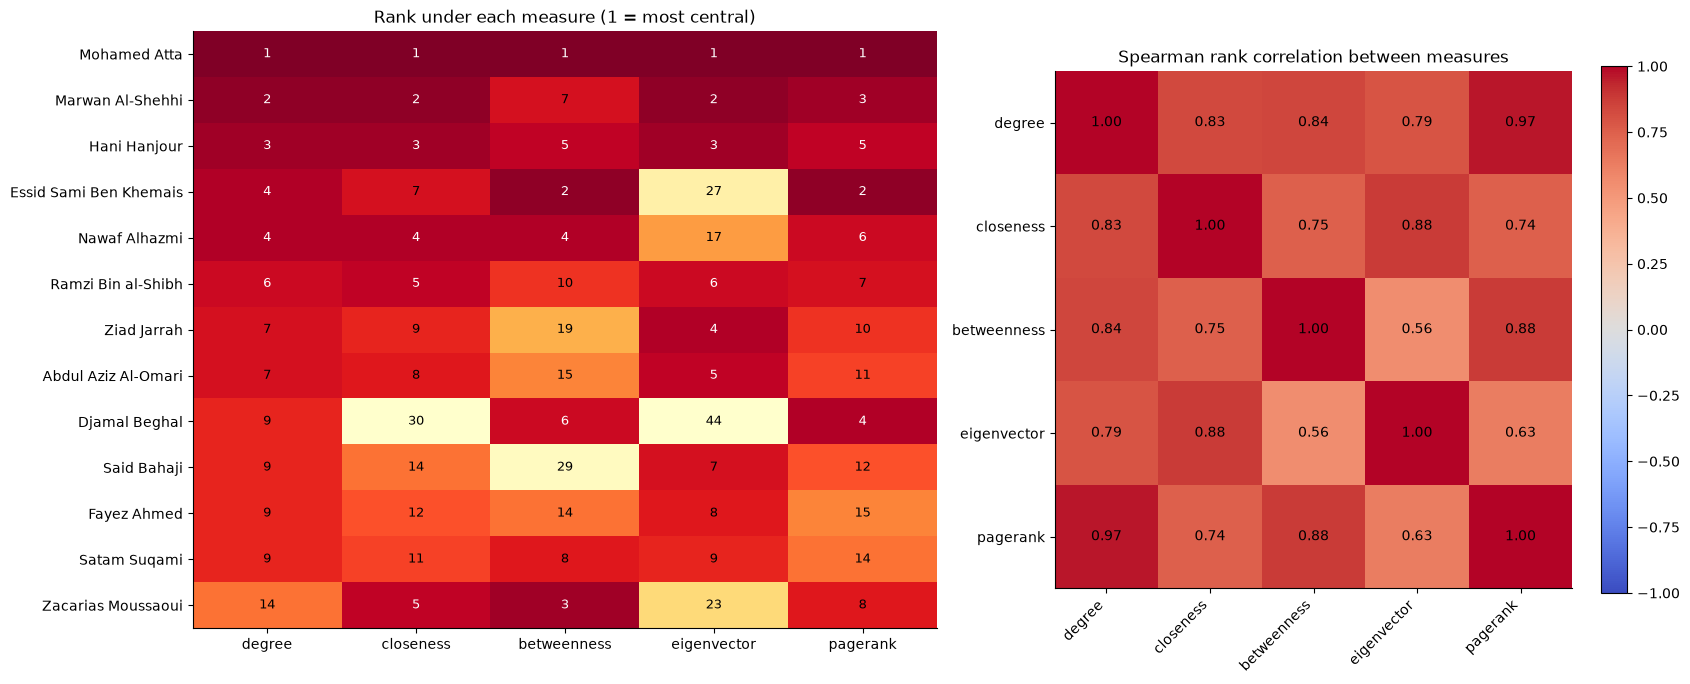

In [19]:
ranks = cent[measures].rank(ascending=False, method="min").astype(int)
ranks.index = cent["name"]
keep = ranks[(ranks <= 8).any(axis=1)].sort_values("degree")

fig, axes = plt.subplots(1, 2, figsize=(17, 7), gridspec_kw={"width_ratios": [1.3, 1]})
im = axes[0].imshow(keep.values, cmap="YlOrRd_r", vmin=1, vmax=30, aspect="auto")
axes[0].set_xticks(range(len(measures))); axes[0].set_xticklabels(measures)
axes[0].set_yticks(range(len(keep))); axes[0].set_yticklabels(keep.index)
for i in range(keep.shape[0]):
    for j in range(keep.shape[1]):
        axes[0].text(j, i, keep.values[i, j], ha="center", va="center", fontsize=9,
                     color="white" if keep.values[i, j] <= 6 else "black")
axes[0].set_title("Rank under each measure (1 = most central)")

corr = cent[measures].corr(method="spearman")
im2 = axes[1].imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
axes[1].set_xticks(range(len(measures))); axes[1].set_xticklabels(measures, rotation=45, ha="right")
axes[1].set_yticks(range(len(measures))); axes[1].set_yticklabels(measures)
for i in range(len(measures)):
    for j in range(len(measures)):
        axes[1].text(j, i, f"{corr.values[i, j]:.2f}", ha="center", va="center")
axes[1].set_title("Spearman rank correlation between measures")
plt.colorbar(im2, ax=axes[1], fraction=0.046)
plt.tight_layout(); plt.show()

### Brokers: high betweenness relative to degree

The most informative comparison is often **betweenness vs degree**. People *above* the trend have more control over flows than their number of contacts would suggest: they are **brokers** linking otherwise separate groups.

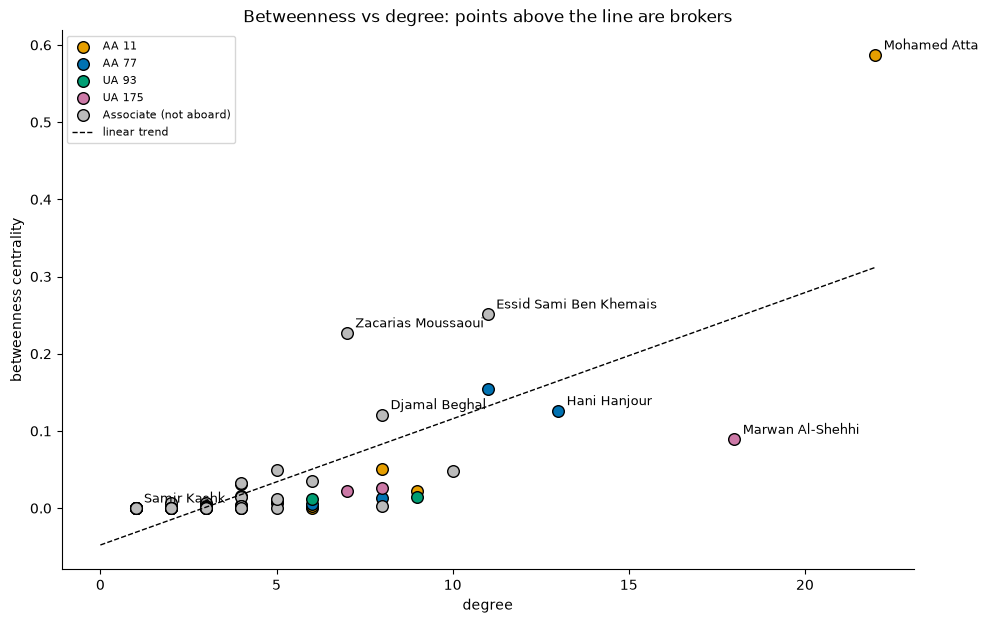

Largest positive residuals (more betweenness than degree predicts):
                        degree  betweenness  residual
name                                                 
Mohamed Atta              22.0        0.587     0.275
Zacarias Moussaoui         7.0        0.227     0.160
Essid Sami Ben Khemais    11.0        0.251     0.119
Djamal Beghal              8.0        0.121     0.038
Samir Kashk                1.0        0.000     0.031
Mamduh Mahmud Salim        1.0        0.000     0.031


In [20]:
fig, ax = plt.subplots(figsize=(11, 7))
x, y = cent["degree"] * (n - 1), cent["betweenness"]
for g in range(5):
    msk = pd.Series(group) == g
    ax.scatter(x[msk], y[msk], c=GROUP_COLOR[g], edgecolors="black", s=70, label=GROUP_LABEL[g])
coef = np.polyfit(x, y, 1)
xx = np.linspace(0, x.max(), 50)
ax.plot(xx, np.polyval(coef, xx), "k--", lw=1, label="linear trend")
resid = y - np.polyval(coef, x)
for v in set(resid.nlargest(5).index) | set(x.nlargest(4).index):
    ax.annotate(name[v], (x[v], y[v]), xytext=(6, 4), textcoords="offset points", fontsize=9)
ax.set_xlabel("degree"); ax.set_ylabel("betweenness centrality")
ax.set_title("Betweenness vs degree: points above the line are brokers")
ax.legend(fontsize=8); plt.show()

print("Largest positive residuals (more betweenness than degree predicts):")
print(pd.DataFrame({"degree": x, "betweenness": y, "residual": resid}).assign(name=pd.Series(name))
      .sort_values("residual", ascending=False).head(6).set_index("name").round(3).to_string())

**Interpretation.**

* **Mohamed Atta tops every measure.** He has the most ties, is closest to everyone, and lies on almost **59%** of all shortest paths. By any definition he is the structural center, consistent with his reported role as operational leader.
* **The measures diverge below the top.** **Marwan Al-Shehhi** is 2nd by degree and eigenvector but only 7th by betweenness: his many ties are mostly *inside* the hijacker core, so few paths need to pass through him.
* **Essid Sami Ben Khemais, Zacarias Moussaoui, and Djamal Beghal** rank 2nd, 3rd, and 6th by betweenness despite modest degree (Moussaoui is around 14th by degree). They are the **brokers** connecting the European associate clusters to the core. Removing such a node can disconnect a whole region of the network (see Section 11).
* **Eigenvector centrality** rewards being tied to other hubs, so it favours the dense hijacker core (Jarrah, Al-Omari, Fayez Ahmed rank highly) and largely ignores the European brokers.
* **PageRank** on an undirected graph behaves much like degree. A random walker spends time roughly in proportion to a node's degree, with some boost for nodes whose neighbours have few other options (which is why Ben Khemais and Beghal rank highly).
* The correlation matrix confirms this. Degree and PageRank are almost interchangeable here (ρ ≈ 0.97). The weakest agreement is between **betweenness and eigenvector** (ρ ≈ 0.56): they capture opposite ideas, brokerage *between* groups versus embeddedness *within* the densest group.

**Takeaway:** don't ask "who is most central?" without saying *central for what*. In a covert network, a high-degree node is the most visible, while a high-betweenness, low-degree node may be the most strategically important and the hardest to notice.

## 11. Brokerage, structural holes, and points of vulnerability

Betweenness is a global brokerage measure. Several other measures describe brokerage directly from the graph's structure:

| Measure | Question | Definition |
|---|---|---|
| **Articulation point** (cut vertex) | Whose removal splits the network into pieces? | node whose deletion increases the number of components |
| **Bridge** | Which single tie is the *only* link between two parts? | edge whose deletion increases the number of components |
| **Effective size** (Burt) | How many *non-redundant* contacts does $i$ have? | degree minus the average number of ties each contact has to $i$'s other contacts |
| **Constraint** (Burt) | How much are $i$'s contacts tied to each other, "boxing $i$ in"? | $c_i = \sum_j \bigl(p_{ij} + \sum_{q} p_{iq}p_{qj}\bigr)^2$, with $p_{ij}$ the share of $i$'s ties invested in $j$ |

Ronald Burt's theory of **structural holes** says actors gain information and control advantages when they connect people who are otherwise *not* connected (low constraint, high effective size).

Articulation points: ['Essid Sami Ben Khemais', 'Djamal Beghal', 'Nawaf Alhazmi', 'Mamoun Darkazanli', 'Mohamed Atta']

Bridges (10):
   Samir Kashk — Essid Sami Ben Khemais
   Essid Sami Ben Khemais — Madjid Sahoune
   Essid Sami Ben Khemais — Fahid al Shakri
   Mohamed Atta — Abdelghani Mzoudi
   Mohamed Atta — Ahmed Khalil Ibrahim Samir Al-Ani
   Djamal Beghal — Jean-Marc Grandvisir
   Djamal Beghal — Abu Zubeida
   Djamal Beghal — Mizar Trabelsi
   Mamoun Darkazanli — Mamduh Mahmud Salim
   Nawaf Alhazmi — Mohamed Abdi


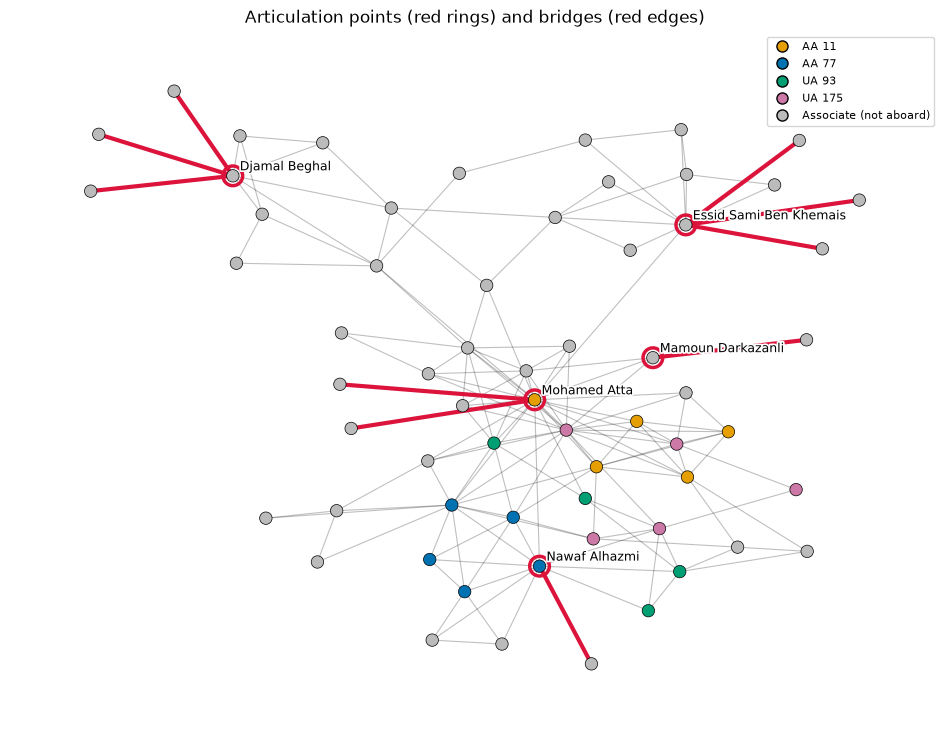

In [21]:
art = list(nx.articulation_points(G))
brg = list(nx.bridges(G))
print("Articulation points:", [name[v] for v in art])
print(f"\nBridges ({len(brg)}):")
for u, v in brg:
    print(f"   {name[u]} — {name[v]}")

draw_network(G, pos, color_by_group=True, label_nodes=art, highlight_nodes=art, highlight_edges=brg,
             title="Articulation points (red rings) and bridges (red edges)", font_size=9)
plt.show()

In [22]:
burt = pd.DataFrame({
    "degree": pd.Series(deg),
    "effective size": pd.Series(nx.effective_size(G)),
    "constraint": pd.Series(nx.constraint(G)),
    "clustering": pd.Series(clust),
})
burt.index = burt.index.map(name)
burt.sort_values("constraint").head(8)

,degree,effective size,constraint,clustering
Mohamed Atta,22,18.364,0.112,0.173
Marwan Al-Shehhi,18,13.111,0.163,0.288
Essid Sami Ben Khemais,11,9.909,0.179,0.109
Hani Hanjour,13,9.462,0.185,0.295
Nawaf Alhazmi,11,8.636,0.198,0.236
Zacarias Moussaoui,7,5.857,0.222,0.190
Djamal Beghal,8,6.750,0.224,0.179
Hamza Alghamdi,7,5.857,0.224,0.190


### Ego networks: a hub vs a broker

An **ego network** is a node ("ego"), its direct contacts ("alters"), and the ties among those alters. Comparing ego networks makes brokerage visible. Below, Atta's ego network is large and its alters are partly interconnected, whereas Moussaoui's alters fall into separate groups that only he links.

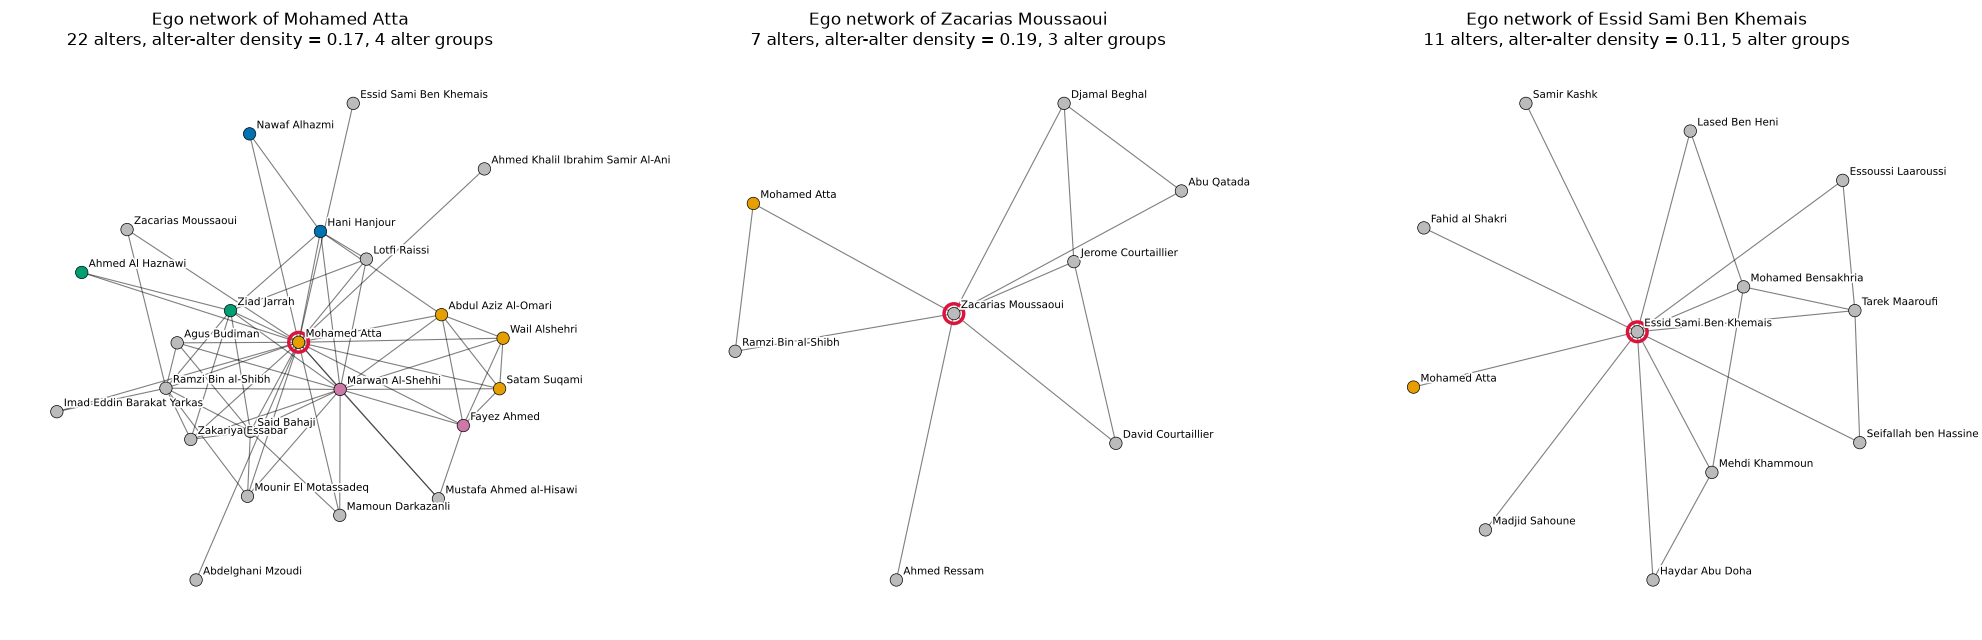

In [23]:
fig, axes = plt.subplots(1, 3, figsize=(20, 6.5))
for ax, ego in zip(axes, ["Mohamed Atta", "Zacarias Moussaoui", "Essid Sami Ben Khemais"]):
    E = nx.ego_graph(G, idx[ego], radius=1)
    alters = E.subgraph([v for v in E if v != idx[ego]])
    p = nx.spring_layout(E, seed=SEED)
    draw_network(E, p, ax=ax, color_by_group=True, label_nodes="all", highlight_nodes=[idx[ego]], font_size=7.5,
                 edge_alpha=0.5,
                 title=f"Ego network of {ego}\n{alters.number_of_nodes()} alters, "
                       f"alter-alter density = {nx.density(alters):.2f}, "
                       f"{nx.number_connected_components(alters)} alter groups")
    ax.get_legend().remove()
plt.tight_layout(); plt.show()

**Interpretation.**

* Five people are **articulation points**: Atta, Ben Khemais, Beghal, Darkazanli, and Nawaf Alhazmi. Each is the *only* link between some part of the network and the rest. There are 10 bridges, all attached to one of these five.
* Most of what hangs off the cut points is small (single associates), but **Ben Khemais** and **Beghal** each hold together a cluster of European associates. Without them, those clusters would be completely disconnected from the core *in this data*.
* **Low constraint and high effective size** identify the same people from a different angle. Atta's 22 contacts behave like about 18 independent ones, so he spans many structural holes.
* The ego networks make this concrete. Removing the ego from the picture splits Moussaoui's and Ben Khemais' alters into several separate groups: their position is pure brokerage.

## 12. Cohesive subgroups: cliques, k-cores, communities

Next, look at the structure between individuals and the whole network: **groups**. Different definitions of "group" give different answers.

### 12.1 Cliques

A **clique** is a set of nodes where *everyone is tied to everyone*. It is the strictest definition of a group. A *maximal* clique cannot be enlarged by adding another node.

* **Question:** *What are the fully interconnected teams?*

Maximal cliques by size: {2: 18, 3: 24, 4: 9, 5: 4, 6: 3}
  size 6: ['Abdul Aziz Al-Omari', 'Fayez Ahmed', 'Marwan Al-Shehhi', 'Mohamed Atta', 'Satam Suqami', 'Wail Alshehri']
  size 6: ['Marwan Al-Shehhi', 'Mohamed Atta', 'Ramzi Bin al-Shibh', 'Said Bahaji', 'Zakariya Essabar', 'Ziad Jarrah']
  size 6: ['Abdul Aziz Al-Omari', 'Fayez Ahmed', 'Marwan Al-Shehhi', 'Satam Suqami', 'Wail Alshehri', 'Waleed Alshehri']


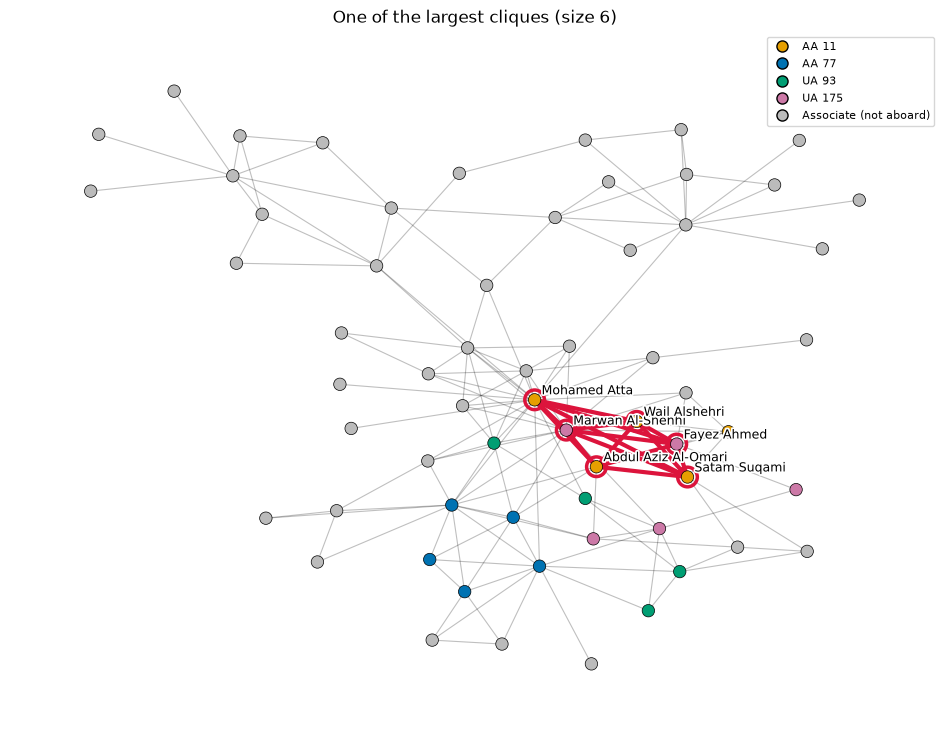

In [24]:
cliques = list(nx.find_cliques(G))
print("Maximal cliques by size:", dict(sorted(Counter(len(c) for c in cliques).items())))
biggest = [c for c in cliques if len(c) == max(map(len, cliques))]
for c in biggest:
    print(f"  size {len(c)}:", sorted(name[v] for v in c))

clique_edges = [(u, v) for u in biggest[0] for v in biggest[0] if u < v]
draw_network(G, pos, color_by_group=True, label_nodes=biggest[0], highlight_nodes=biggest[0],
             highlight_edges=clique_edges, title="One of the largest cliques (size 6)", font_size=9)
plt.show()

There are three maximal cliques of size 6. Two consist entirely of hijackers from AA 11 and UA 175, the teams of Atta and Al-Shehhi. The third is the **Hamburg circle**: the pilots Atta, Al-Shehhi, and Jarrah together with Ramzi Bin al-Shibh, Said Bahaji, and Zakariya Essabar. Cliques are rigid, though: missing a single tie breaks one. In incomplete data like this, a looser definition is often more useful.

### 12.2 k-cores

The **k-core** is the maximal subgraph in which every node has at least $k$ ties *within the subgraph*. It is found by repeatedly removing nodes with degree below $k$. A node's **core number** is the largest $k$ for which it belongs to the $k$-core.

* **Question:** *Who forms the most deeply embedded center of the network, as opposed to the periphery?*

Nodes per core number: {1: 10, 2: 15, 3: 17, 4: 9, 5: 11}

5-core members: ['Abdul Aziz Al-Omari', 'Fayez Ahmed', 'Marwan Al-Shehhi', 'Mohamed Atta', 'Ramzi Bin al-Shibh', 'Said Bahaji', 'Satam Suqami', 'Wail Alshehri', 'Waleed Alshehri', 'Zakariya Essabar', 'Ziad Jarrah']


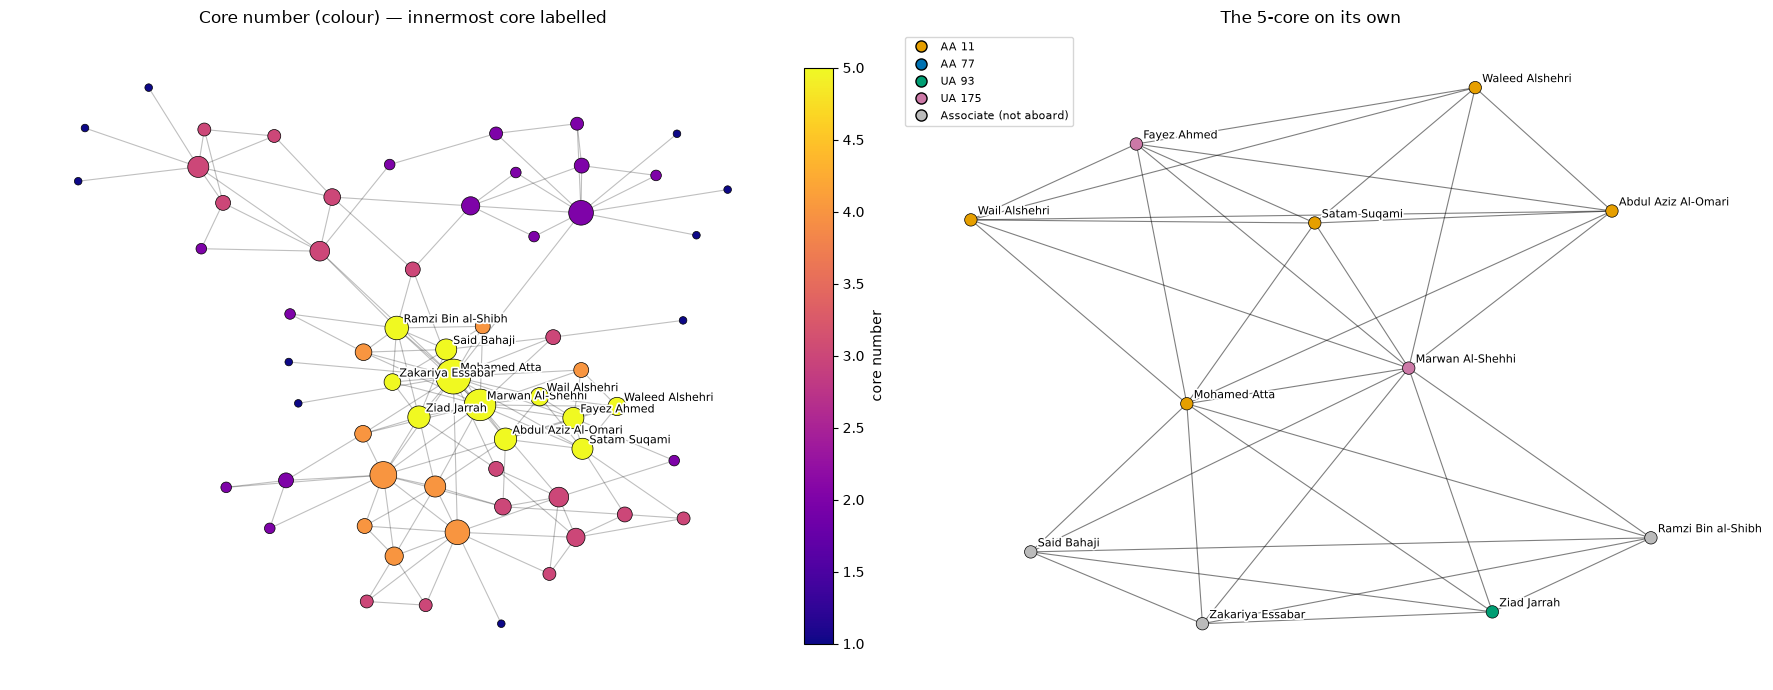

In [25]:
core = nx.core_number(G)
kmax = max(core.values())
print("Nodes per core number:", dict(sorted(Counter(core.values()).items())))
print(f"\n{kmax}-core members:", sorted(name[v] for v, c in core.items() if c == kmax))

fig, axes = plt.subplots(1, 2, figsize=(18, 7))
draw_network(G, pos, ax=axes[0], values=core, size=deg, cmap="plasma", top_k=0, label_nodes=[v for v in G if core[v] == kmax],
             title="Core number (colour) — innermost core labelled", colorbar_label="core number", font_size=8)
Hk = nx.k_core(G, kmax)
draw_network(Hk, nx.spring_layout(Hk, seed=SEED), ax=axes[1], color_by_group=True, label_nodes="all",
             title=f"The {kmax}-core on its own", font_size=8, edge_alpha=0.5)
plt.tight_layout(); plt.show()

**Interpretation.** The innermost **5-core** has 11 people. Eight are hijackers, including all three of the pilots from the Hamburg circle (Atta, Al-Shehhi, Jarrah), together with Hamburg associates such as Ramzi Bin al-Shibh and Said Bahaji. This is the network's dense nucleus. The European clusters, by contrast, sit in low cores (their brokers Ben Khemais, Beghal, and Moussaoui have core numbers of only 2–3): they are attached to the network but not deeply embedded in it.

### 12.3 Community detection and modularity

**Communities** are groups with many ties *inside* and relatively few ties *between* them; unlike cliques they don't require completeness. The standard quality score is **modularity**:

$$Q = \frac{1}{2m}\sum_{ij}\left[A_{ij} - \frac{k_ik_j}{2m}\right]\delta(c_i, c_j)$$

This compares the number of within-community ties to the number expected if ties were rewired at random keeping degrees fixed. $Q=0$ means no better than chance; values above about 0.3 usually indicate clear community structure.

* **Question:** *What groups does the network naturally divide into, and do they match known roles (here, flights)?*

We use the **Louvain** algorithm, which greedily optimizes $Q$. It involves randomness, so we fix a seed and then check stability across seeds.

In [26]:
comms = sorted(nx.community.louvain_communities(G, seed=SEED), key=len, reverse=True)
comm_of = {v: i for i, c in enumerate(comms) for v in c}
Q = nx.community.modularity(G, comms)
flight_partition = [{v for v in G if group[v] == g} for g in range(5)]
Q_flight = nx.community.modularity(G, flight_partition)
print(f"Louvain: {len(comms)} communities, modularity Q = {Q:.3f}")
print(f"Partition by flight group (5 groups): Q = {Q_flight:.3f}")
for i, c in enumerate(comms):
    hij = sorted(name[v] for v in c if group[v] < 4)
    print(f"\nCommunity {i} ({len(c)} people, {len(hij)} hijackers): ", ", ".join(sorted(name[v] for v in c)))

ct = pd.crosstab(pd.Series(comm_of).rename("community"), pd.Series(group).map(GROUP_LABEL).rename("flight group"))
ct

Louvain: 6 communities, modularity Q = 0.532
Partition by flight group (5 groups): Q = 0.223

Community 0 (14 people, 3 hijackers):  Abdelghani Mzoudi, Agus Budiman, Ahmed Khalil Ibrahim Samir Al-Ani, Lotfi Raissi, Mamduh Mahmud Salim, Mamoun Darkazanli, Marwan Al-Shehhi, Mohamed Atta, Mohammed Belfas, Mounir El Motassadeq, Ramzi Bin al-Shibh, Said Bahaji, Zakariya Essabar, Ziad Jarrah

Community 1 (12 people, 0 hijackers):  Ahmed Ressam, Essid Sami Ben Khemais, Essoussi Laaroussi, Fahid al Shakri, Haydar Abu Doha, Lased Ben Heni, Madjid Sahoune, Mehdi Khammoun, Mohamed Bensakhria, Samir Kashk, Seifallah ben Hassine, Tarek Maaroufi

Community 2 (12 people, 6 hijackers):  Abdussattar Shaikh, Ahmed Alghamdi, Bandar Alhazmi, Hani Hanjour, Khalid Al-Mihdhar, Majed Moqed, Mohamed Abdi, Nawaf Alhazmi, Osama Awadallah, Raisal Al Salmi, Rayed Mohammed Abdullah, Salem Alhazmi

Community 3 (11 people, 0 hijackers):  Abu Qatada, Abu Walid, Abu Zubeida, David Courtaillier, Djamal Beghal, Imad Eddi

flight group,AA 11,AA 77,Associate (not aboard),UA 175,UA 93
community,,,,,
0,1,0,11,1,1
1,0,0,12,0,0
2,0,5,6,1,0
3,0,0,11,0,0
4,0,0,2,2,3
5,4,0,1,1,0


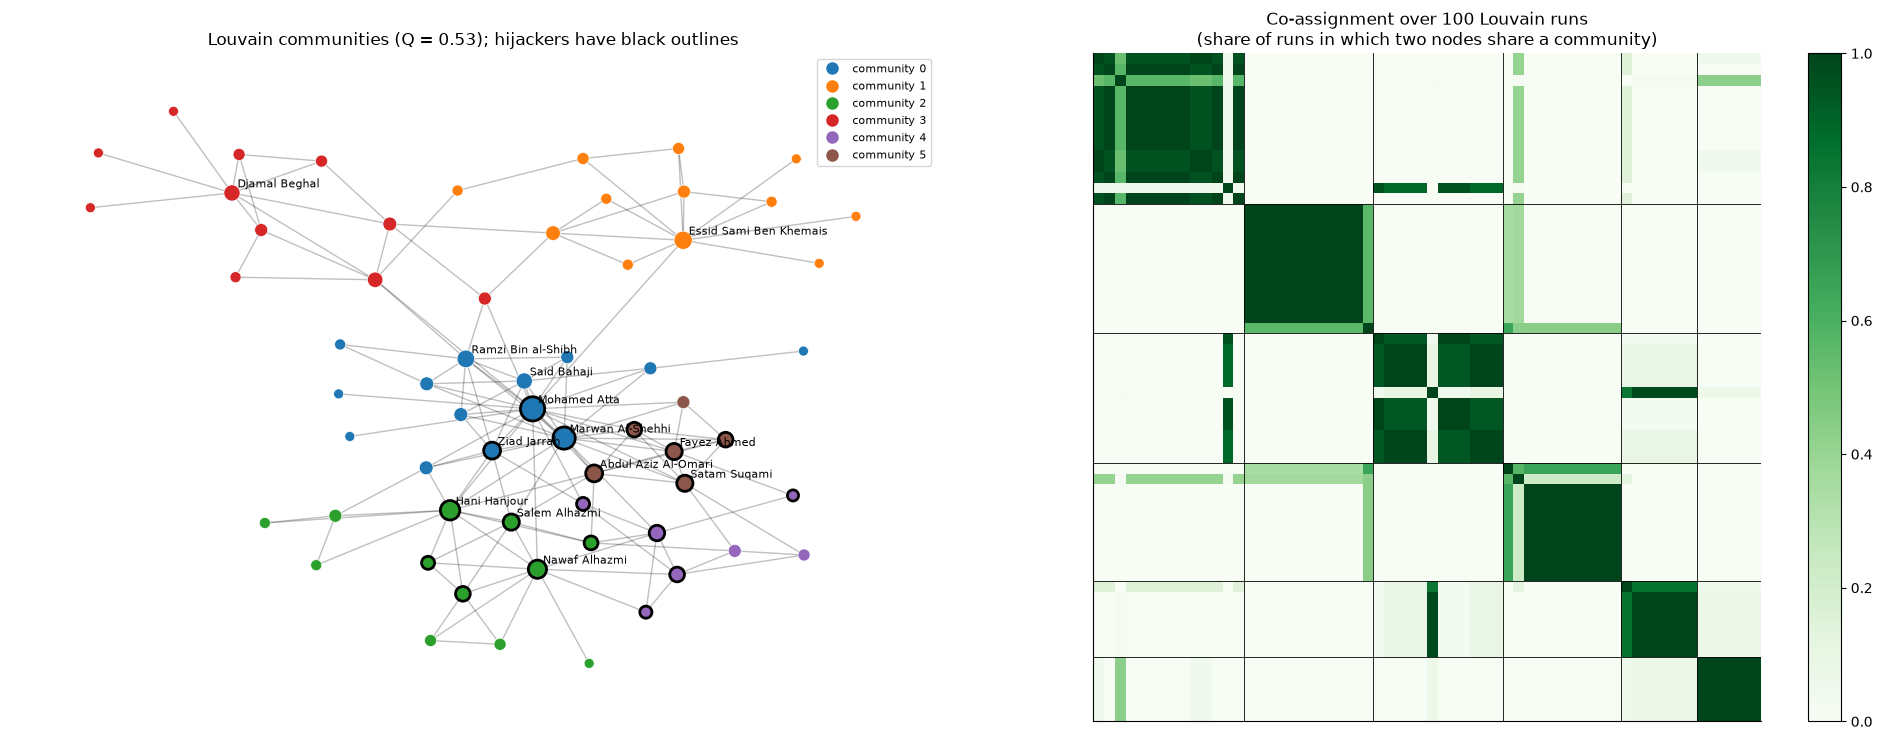

Across seeds: Q between 0.517 and 0.534; communities found: {6: 90, 5: 10}


In [27]:
cmap_c = plt.get_cmap("tab10")
fig, axes = plt.subplots(1, 2, figsize=(19, 7.5))
ax = axes[0]
nx.draw_networkx_edges(G, pos, ax=ax, alpha=0.25)
nx.draw_networkx_nodes(G, pos, node_color=[cmap_c(comm_of[v]) for v in G], node_size=[40 + 12 * deg[v] for v in G],
                       edgecolors=["black" if group[v] < 4 else "white" for v in G], linewidths=[2 if group[v] < 4 else 0.5 for v in G], ax=ax)
for v in G:
    if deg[v] >= 8:
        ax.annotate(name[v], pos[v], xytext=(4, 4), textcoords="offset points", fontsize=8)
ax.legend(handles=[Line2D([0], [0], marker="o", ls="", markerfacecolor=cmap_c(i), markeredgecolor="none", markersize=9,
                          label=f"community {i}") for i in range(len(comms))], fontsize=8)
ax.set_title(f"Louvain communities (Q = {Q:.2f}); hijackers have black outlines"); ax.axis("off")

# Stability across seeds: how often does each pair of nodes land in the same community?
runs = [nx.community.louvain_communities(G, seed=s) for s in range(100)]
qs = [nx.community.modularity(G, r) for r in runs]
ks = [len(r) for r in runs]
corder = sorted(G, key=lambda v: (comm_of[v], group[v]))
pidx = {v: i for i, v in enumerate(corder)}
co = np.zeros((n, n))
for r in runs:
    for c in r:
        ii = [pidx[v] for v in c]
        co[np.ix_(ii, ii)] += 1
co /= len(runs)
ax = axes[1]
im = ax.imshow(co, cmap="Greens", vmin=0, vmax=1)
cb_ = np.cumsum([len(c) for c in comms])
for b_ in cb_[:-1]:
    ax.axhline(b_ - 0.5, color="black", lw=0.6); ax.axvline(b_ - 0.5, color="black", lw=0.6)
ax.set_xticks([]); ax.set_yticks([])
ax.set_title("Co-assignment over 100 Louvain runs\n(share of runs in which two nodes share a community)")
plt.colorbar(im, ax=ax, fraction=0.046)
plt.tight_layout(); plt.show()
print(f"Across seeds: Q between {min(qs):.3f} and {max(qs):.3f}; communities found: {dict(Counter(ks))}")

**Interpretation.**

* Modularity of about **0.53** indicates strong community structure. The co-assignment matrix shows it is stable across random seeds: the dark diagonal blocks reappear in almost every run, and only a few boundary nodes (the lighter stripes) switch communities. Reporting this kind of stability check is good practice whenever an algorithm has a random component.
* The communities are **not the flight teams.** The flight partition has a much lower $Q$ (≈0.22), largely because the 43 associates form one big "group" in that partition that isn't cohesive. More interesting is how the *hijackers* are split:
  * The three pilots from Hamburg (**Atta, Al-Shehhi, Jarrah**) fall into one community with the Hamburg associates (Bin al-Shibh, Bahaji, Essabar, Motassadeq, …), *not* with the other members of their own flights.
  * The AA 77 team falls into a community with associates linked to their time in the United States.
  * The remaining hijackers form their own communities, with team members partly mixed across flights.
  * The European associates form two separate communities, centred on Ben Khemais and on Beghal/Moussaoui.
* The network's groups therefore reflect **where people came from and who they lived and trained with** (prior social circles) more than the **operational assignment** to flights. Community detection reveals a latent organization that the attribute alone wouldn't show.

## 13. Mixing patterns: assortativity and homophily

**Assortativity** asks whether ties connect *similar* or *dissimilar* nodes.

| Measure | Question | Range / meaning |
|---|---|---|
| **Degree assortativity** $r$ | Do hubs connect to hubs (assortative, $r>0$) or to low-degree nodes (disassortative, $r<0$)? | Pearson correlation of degrees at either end of each edge, $-1\le r\le 1$ |
| **Attribute assortativity** | Do people tie mostly within their own category (homophily)? | 1 = perfectly within-group, 0 = random, <0 = mostly between groups |
| **E–I index** (Krackhardt & Stern) | For one group: more external or internal ties? | $\dfrac{E-I}{E+I}$, from −1 (all internal) to +1 (all external) |

degree assortativity r          = -0.080
assortativity by flight group   = +0.323
assortativity hijacker vs not   = +0.460


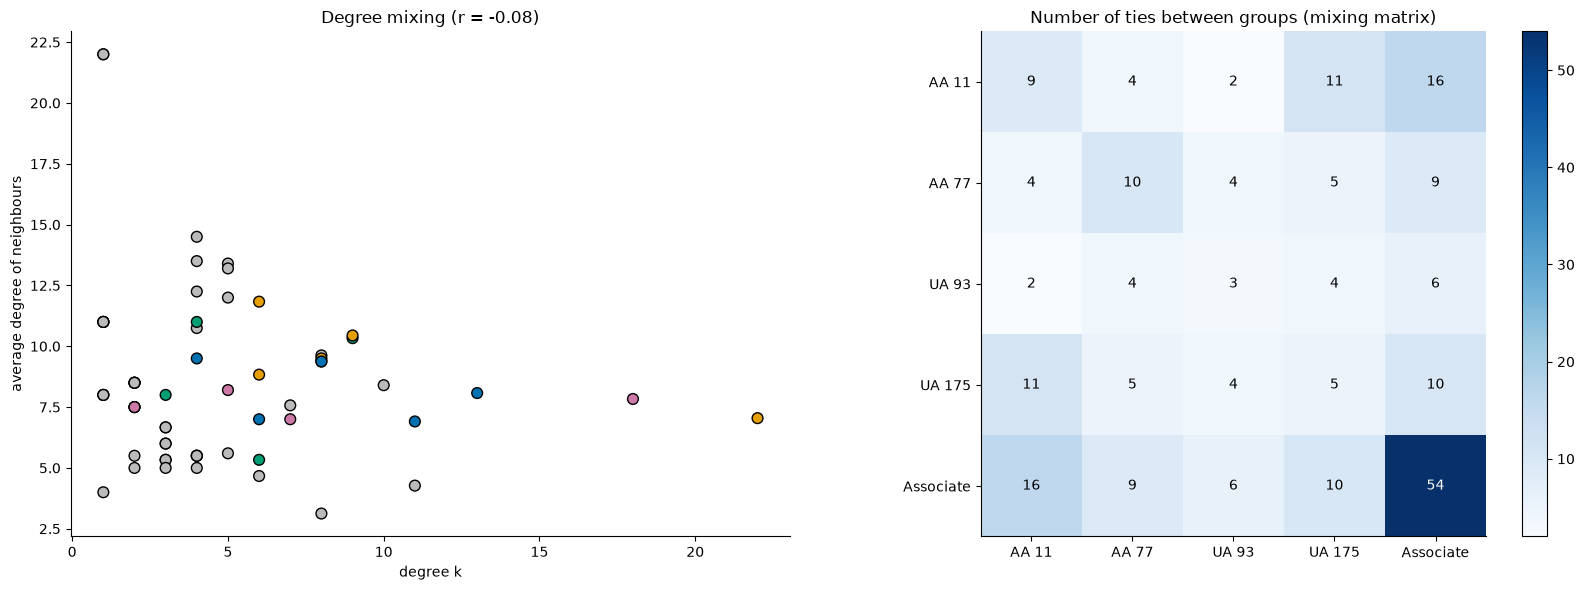

,internal ties I,external ties E,E-I index
group,,,
AA 11,9,33,0.571
AA 77,10,22,0.375
UA 93,3,16,0.684
UA 175,5,30,0.714
Associate (not aboard),54,41,-0.137


In [28]:
r_deg = nx.degree_assortativity_coefficient(G)
r_grp = nx.attribute_assortativity_coefficient(G, "group")
r_hij = nx.attribute_assortativity_coefficient(G, "hijacker")
print(f"degree assortativity r          = {r_deg:+.3f}")
print(f"assortativity by flight group   = {r_grp:+.3f}")
print(f"assortativity hijacker vs not   = {r_hij:+.3f}")

knn = nx.average_neighbor_degree(G)
# tie counts between groups (each undirected tie counted once)
mix = np.zeros((5, 5), dtype=int)
for u, v in G.edges:
    mix[group[u], group[v]] += 1
    if group[u] != group[v]:
        mix[group[v], group[u]] += 1

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
axes[0].scatter([deg[v] for v in G], [knn[v] for v in G], c=[GROUP_COLOR[group[v]] for v in G], edgecolors="black", s=60)
axes[0].set_xlabel("degree k"); axes[0].set_ylabel("average degree of neighbours")
axes[0].set_title(f"Degree mixing (r = {r_deg:+.2f})")
labels_short = [GROUP_LABEL[g].split(" (")[0] for g in range(5)]
im = axes[1].imshow(mix, cmap="Blues")
axes[1].set_xticks(range(5)); axes[1].set_xticklabels(labels_short)
axes[1].set_yticks(range(5)); axes[1].set_yticklabels(labels_short)
for i in range(5):
    for j in range(5):
        axes[1].text(j, i, mix[i, j], ha="center", va="center",
                     color="white" if mix[i, j] > mix.max() / 2 else "black")
axes[1].set_title("Number of ties between groups (mixing matrix)")
plt.colorbar(im, ax=axes[1], fraction=0.046)
plt.tight_layout(); plt.show()

# E-I index per group
rows = []
for g in range(5):
    I = sum(1 for u, v in G.edges if group[u] == g and group[v] == g)
    E = sum(1 for u, v in G.edges if (group[u] == g) != (group[v] == g))
    rows.append({"group": GROUP_LABEL[g], "internal ties I": I, "external ties E": E, "E-I index": (E - I) / (E + I)})
pd.DataFrame(rows).set_index("group")

**Interpretation.**

* **Degree assortativity is slightly negative** (≈ −0.08, close to neutral). Hubs are not especially tied to other hubs; many low-degree associates hang off a few hubs. Disassortative or near-neutral mixing is common in networks organized around hubs and "spokes".
* **Strong homophily by role:** the hijacker/non-hijacker assortativity of ≈ +0.46 means hijackers are tied to other hijackers far more than chance would predict.
* **The E–I index** is positive for every flight team, meaning each team has more ties *outside* than inside. Teams are tiny, though (at most 10 possible internal ties), so look at saturation too. The AA 77 team has all 10 of its possible internal ties (a complete clique) and AA 11 has 9 of 10, whereas UA 175 has only 5 of 10. The associates, as a large group, have more internal than external ties (E–I < 0).

## 14. Zooming in: the 19 hijackers

An **induced subgraph** keeps a subset of nodes and all ties among them. Restricting to the hijackers lets us ask how the operational group itself was structured, and how it compares to the full network.

Graph with 19 nodes and 57 edges
density of hijacker subgraph = 0.333  (whole network: 0.080)
connected: True, diameter = 3, avg path length = 1.83
mean distance, same flight = 1.28; different flights = 1.98


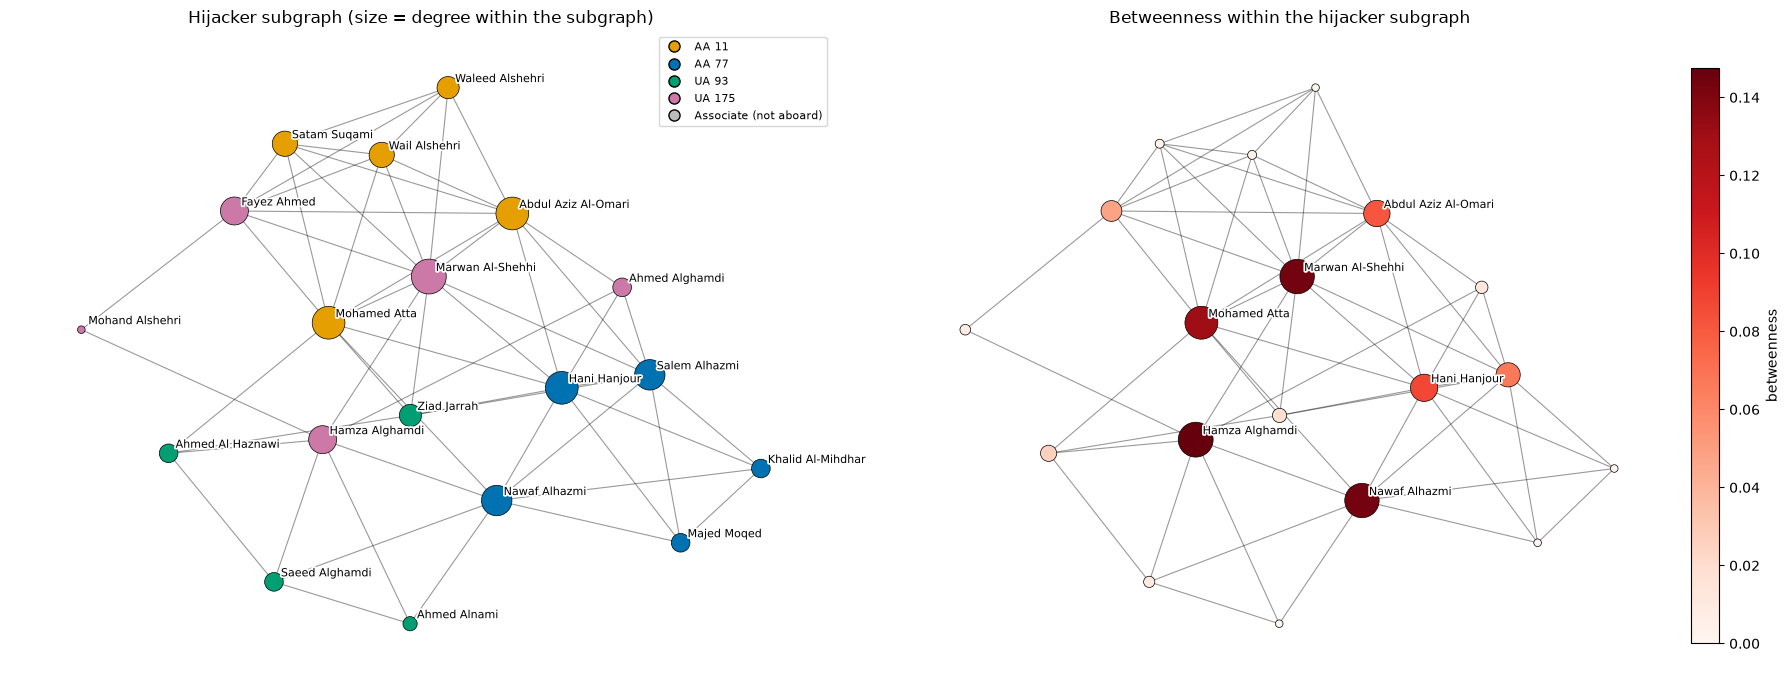

,flight,degree in H,betweenness in H
Hamza Alghamdi,UA 175,7,0.148
Marwan Al-Shehhi,UA 175,10,0.144
Nawaf Alhazmi,AA 77,8,0.143
Mohamed Atta,AA 11,9,0.131
Hani Hanjour,AA 77,9,0.087
Abdul Aziz Al-Omari,AA 11,9,0.081
Salem Alhazmi,AA 77,8,0.067
Fayez Ahmed,UA 175,7,0.048


In [29]:
hij_nodes = [v for v in G if group[v] < 4]
H = G.subgraph(hij_nodes).copy()
print(H)
print(f"density of hijacker subgraph = {nx.density(H):.3f}  (whole network: {nx.density(G):.3f})")
print(f"connected: {nx.is_connected(H)}, diameter = {nx.diameter(H)}, avg path length = {nx.average_shortest_path_length(H):.2f}")

# within-team vs between-team distance (in the hijacker subgraph)
dH = dict(nx.all_pairs_shortest_path_length(H))
within = [dH[u][v] for u in H for v in H if u < v and group[u] == group[v]]
between = [dH[u][v] for u in H for v in H if u < v and group[u] != group[v]]
print(f"mean distance, same flight = {np.mean(within):.2f}; different flights = {np.mean(between):.2f}")

bH = nx.betweenness_centrality(H)
pH = nx.kamada_kawai_layout(H)
fig, axes = plt.subplots(1, 2, figsize=(18, 7))
draw_network(H, pH, ax=axes[0], color_by_group=True, label_nodes="all", size=dict(H.degree()), font_size=8, edge_alpha=0.4,
             title="Hijacker subgraph (size = degree within the subgraph)")
draw_network(H, pH, ax=axes[1], values=bH, cmap="Reds", top_k=6, font_size=8, edge_alpha=0.4,
             title="Betweenness within the hijacker subgraph", colorbar_label="betweenness")
plt.tight_layout(); plt.show()

pd.DataFrame({"flight": pd.Series({v: GROUP_LABEL[group[v]] for v in H}),
              "degree in H": pd.Series(dict(H.degree())),
              "betweenness in H": pd.Series(bH)}).rename(index=name).sort_values("betweenness in H", ascending=False).head(8)

**Interpretation.**

* Among themselves the hijackers are about **4× denser** than the network as a whole (≈0.33 vs 0.08) and form a single connected group with a diameter of only 3.
* Members of the same flight are on average closer to each other (≈1.3 steps) than to members of other flights (≈2 steps). Each team was internally cohesive.
* Within the hijacker group, betweenness is spread much more **evenly** than in the full network. Hamza Alghamdi, Marwan Al-Shehhi, Nawaf Alhazmi, and Mohamed Atta all have similar values. Atta's overwhelming betweenness in the full network therefore comes mainly from linking the hijackers to the *associate* clusters (Hamburg, Europe), not from holding the hijackers together. This shows that a centrality score depends on where you draw the network boundary.

This dataset merges several kinds of association into one tie type. Krebs' original analysis separated layers such as "trusted prior contacts", which are much sparser than the combined graph. Conclusions like "teams were tightly knit" depend strongly on **which ties are included** in the data.

## 15. Robustness: how does the network fragment?

A final classic question: *How resilient is this network to the removal of nodes?* This is the core of percolation and network-resilience analysis, used for infrastructure, epidemics (vaccination targeting), and the study of criminal networks.

We remove nodes one at a time using different strategies and track:

* the **relative size of the largest connected component** (can the network still act as one unit?), and
* **global efficiency** (how quickly could information still travel?).

Strategies: **random** removal (averaged over many runs), **targeted by degree**, and **targeted by betweenness**, recomputed after each removal ("adaptive").

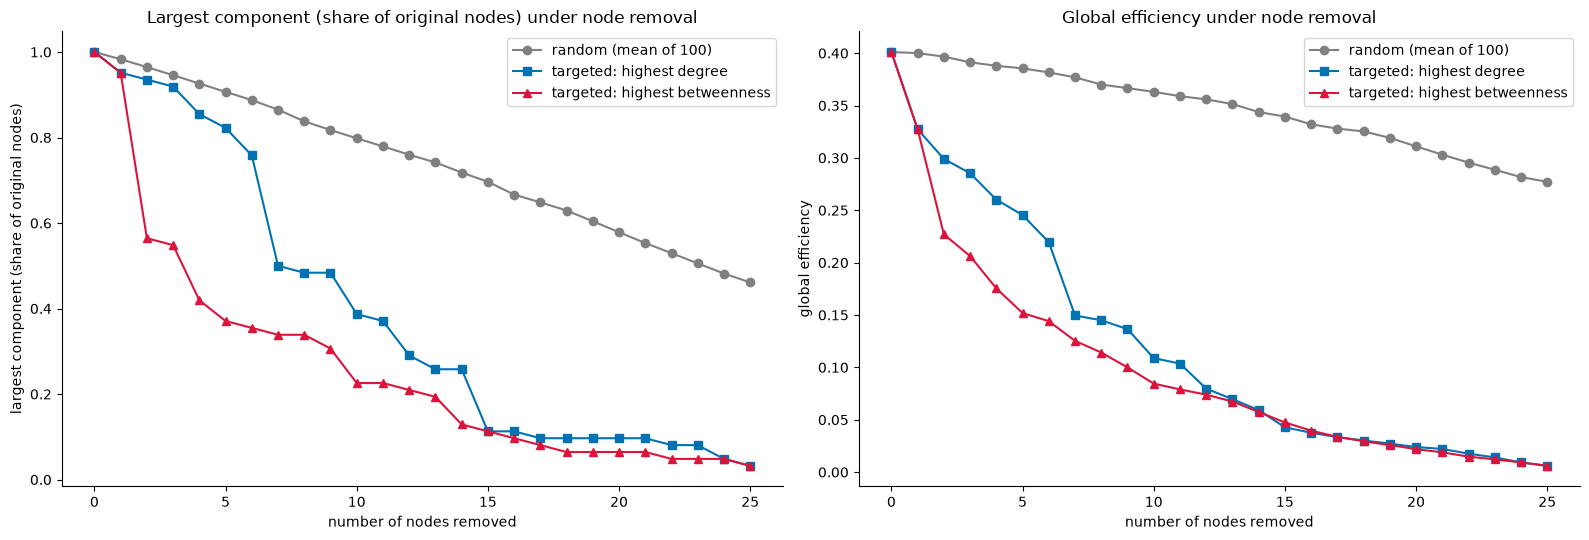

First 6 removed (betweenness, adaptive): ['Mohamed Atta', 'Ramzi Bin al-Shibh', 'Marwan Al-Shehhi', 'Ziad Jarrah', 'Hani Hanjour', 'Abu Qatada']
First 6 removed (degree, adaptive):      ['Mohamed Atta', 'Marwan Al-Shehhi', 'Hani Hanjour', 'Essid Sami Ben Khemais', 'Nawaf Alhazmi', 'Djamal Beghal']
after removing 1: LCC random = 0.98, degree = 0.95, betweenness = 0.95
after removing 3: LCC random = 0.95, degree = 0.92, betweenness = 0.55
after removing 5: LCC random = 0.91, degree = 0.82, betweenness = 0.37


In [30]:
def attack_curve(G, strategy, steps=25, seed=0):
    H = G.copy()
    r = np.random.default_rng(seed)
    lcc, eff, removed = [], [], []
    for _ in range(steps + 1):
        lcc.append(len(max(nx.connected_components(H), key=len)) / G.number_of_nodes() if H.number_of_nodes() else 0)
        eff.append(nx.global_efficiency(H))
        if H.number_of_nodes() == 0:
            break
        if strategy == "random":
            v = r.choice(list(H.nodes))
        elif strategy == "degree":
            d = dict(H.degree()); v = max(d, key=d.get)
        elif strategy == "betweenness":
            b = nx.betweenness_centrality(H); v = max(b, key=b.get)
        removed.append(v)
        H.remove_node(v)
    return np.array(lcc), np.array(eff), removed

STEPS = 25
curves = {s: attack_curve(G, s, STEPS) for s in ["degree", "betweenness"]}
rand_runs = [attack_curve(G, "random", STEPS, seed=s) for s in range(100)]
rand_lcc = np.mean([r[0] for r in rand_runs], axis=0)
rand_eff = np.mean([r[1] for r in rand_runs], axis=0)

fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))
xs = np.arange(STEPS + 1)
for ax, k, rnd, lab in [(axes[0], 0, rand_lcc, "largest component (share of original nodes)"),
                        (axes[1], 1, rand_eff, "global efficiency")]:
    ax.plot(xs, rnd, "o-", color="grey", label="random (mean of 100)")
    ax.plot(xs, curves["degree"][k], "s-", color="#0072B2", label="targeted: highest degree")
    ax.plot(xs, curves["betweenness"][k], "^-", color="crimson", label="targeted: highest betweenness")
    ax.set_xlabel("number of nodes removed"); ax.set_ylabel(lab); ax.legend()
    ax.set_title(lab.capitalize() + " under node removal")
plt.tight_layout(); plt.show()

print("First 6 removed (betweenness, adaptive):", [name[v] for v in curves["betweenness"][2][:6]])
print("First 6 removed (degree, adaptive):     ", [name[v] for v in curves["degree"][2][:6]])
for k in [1, 3, 5]:
    print(f"after removing {k}: LCC random = {rand_lcc[k]:.2f}, degree = {curves['degree'][0][k]:.2f}, betweenness = {curves['betweenness'][0][k]:.2f}")

**Interpretation.**

* **Random removal** degrades the network slowly. Removing a few random people barely changes anything, because most nodes are peripheral.
* **Targeted removal** is much more damaging. Removing Atta alone barely shrinks the largest component, but it cuts global efficiency by almost a fifth, since many shortest paths ran through him. Removing next the new top-betweenness node (Ramzi Bin al-Shibh, the link to the European clusters) cuts the largest component to under 60% of the network. After 5 targeted removals it is below 40%, while random removal of 5 people still leaves about 90% connected.
* This **"robust to random failure, fragile to targeted attack"** pattern is typical of networks with heterogeneous degrees and a few critical brokers (Albert, Jeong & Barabási, 2000).
* Betweenness-based removal fragments the network faster than degree-based removal. It targets the brokers holding separate regions together, not just the nodes with the most contacts.
* An important caveat: real covert networks **adapt**, because removed roles get filled and new ties form. A static simulation on incomplete data is a structural thought experiment, not a forecast.

## 16. Summary cheat sheet

| Level | Measure | Question it answers | In this network |
|---|---|---|---|
| Whole network | Density | What share of possible ties exist? | ≈ 0.08: sparse |
| | Components | Is everyone reachable? | 1 component: fully connected |
| | Avg path length / diameter | How far apart are people? | ≈ 2.9 / 5: short |
| | Transitivity | How cliquish is the network? | ≈ 0.36: ~5× random |
| | Small-world comparison | Is clustering/path length unusual vs chance? | high C, near-random L: small world |
| | Degree assortativity | Do hubs connect to hubs? | ≈ −0.08: roughly neutral |
| | Modularity | Does it split into groups? | Q ≈ 0.53: strong communities |
| | Robustness curves | How does it fragment under removal? | robust to random, fragile to targeted |
| Groups | Cliques | Fully connected teams? | max size 6, mostly hijackers |
| | k-cores | Who is in the dense nucleus? | 5-core of 11, built around the Hamburg pilots |
| | Communities | Natural groupings? | prior social circles, not flight teams |
| | Attribute assortativity / E–I | Homophily by role? | hijackers strongly tied to hijackers |
| Individuals | Degree | Who has most contacts? | Atta, Al-Shehhi, Hanjour |
| | Closeness / eccentricity | Who reaches everyone fastest? | Atta |
| | Betweenness | Who controls flows between groups? | Atta, then brokers Ben Khemais, Moussaoui |
| | Eigenvector / PageRank | Who is tied to the well-connected? | the hijacker core |
| | Clustering | Is one's neighbourhood tight-knit? | high for peripheral nodes, low for hubs |
| | Constraint / effective size | Who spans structural holes? | Atta, Al-Shehhi, Ben Khemais |
| | Articulation points / bridges | Whose removal disconnects the network? | 5 cut nodes, 10 bridges |

## 17. Caveats and further reading

**Data limitations.**

* **Missing data.** The network was reconstructed from press reports after the attacks. Covert networks are, by design, hard to observe, so many ties are surely missing. Missing ties affect measures unequally: betweenness and path-based measures are particularly sensitive, since a single missing tie can reroute many shortest paths.
* **Boundary specification.** Who counts as an "associate" was decided by the data compiler. Associates who appear via a single press mention end up with degree 1 and inflate the periphery.
* **No weights, types, or timing.** A shared apartment, a single phone call, and years of friendship all count as one undirected tie. Krebs' original work distinguished tie strengths; this version does not.
* **Hindsight.** It is much easier to find the "key players" when you already know who they were. Applying these methods *prospectively* is far harder.
* **Group labels.** The mapping of groups 0–3 to specific flights is inferred from public records of who was aboard each flight, not documented in the source data.

**Further reading.**

* V. Krebs (2002). Mapping networks of terrorist cells. *Connections* 24(3), 43–52.
* S. Wasserman & K. Faust (1994). *Social Network Analysis: Methods and Applications.* Cambridge University Press.
* M. E. J. Newman (2018). *Networks* (2nd ed.). Oxford University Press.
* R. S. Burt (1992). *Structural Holes: The Social Structure of Competition.* Harvard University Press.
* D. J. Watts & S. H. Strogatz (1998). Collective dynamics of 'small-world' networks. *Nature* 393, 440–442.
* R. Albert, H. Jeong & A.-L. Barabási (2000). Error and attack tolerance of complex networks. *Nature* 406, 378–382.
* C. Morselli, C. Giguère & K. Petit (2007). The efficiency/security trade-off in criminal networks. *Social Networks* 29(1), 143–153.